# Preparing a UXO recording for Z-Splat

This notebook turns **one** recording of the UXO dataset (DFKI, ARIS sonar + GoPro on a gantry) into a
scene that Z-Splat's own real-sonar reader can load. Z-Splat's reader is the `Underwater` reader on branch
`gaussian-splatting-with-depth-FLS-2` (`scene/dataset_readers.py`, functions `add_cam` and `add_sonar`).
Everything is built from the raw dataset files here, step by step, so every number is visible.

**What Z-Splat needs** (one line per input; each one is explained in the step that builds it):

| Input | Camera | Sonar |
|---|---|---|
| measurements | RGB images | polar sonar images (range x beam) |
| where the sensor was | one **pose** per image | one **pose** per sonar frame |
| how the sensor sees | intrinsics (focal length, principal point), undistorted images | field of view, range window, beam angles |

**Steps**

1. **Raw files and sensor settings** (this part): what was recorded and how the camera and sonar were set up.
2. Time sync: which camera image belongs to which sonar frame.
3. Poses: from gantry position + rotator angles to a 4x4 pose for every camera image and sonar frame.
4. Camera model: intrinsics and undistortion.
5. Sonar geometry: range of each row, angle of each beam.
6. Write the scene and load it with the Z-Splat reader as the final check.

## Background: the rig, and what a pose is

**The rig.** The sensors don't move freely. A gantry ("portal crane") above a water tank moves a
pan-tilt-roll rotator (the "AR3") along x, y and z. The rotator holds both the ARIS sonar and the GoPro, so the
two sensors always move together and keep a fixed offset from each other.

```
        gantry rail (moves x, y, z)          logged per frame: gantry.csv  (x, y, z in m)
   ═════════════╤═══════════════════
                │
             [ AR3 ]  pan / tilt / roll      logged per frame: aris_frame_meta.csv (SonarPan, SonarTilt, SonarRoll in deg)
              /    \
        [ ARIS ]  [ GoPro ]                  fixed offsets: calibration/transforms.yaml
            \       /
             \     /    looking down at the target on the tank floor
              ( UXO )
```

**What a pose is.** A pose is *where a sensor is and which way it points*, at one instant:
a position (3 numbers, metres) and an orientation (a 3x3 rotation). Together they form a 4x4 matrix

```
T_world_sensor = [ R  t ]     R: columns are the sensor's x, y, z axes written in world coordinates
                 [ 0  1 ]     t: the sensor's position in world coordinates
```

It maps a point given in sensor coordinates to world coordinates: `p_world = R @ p_sensor + t`.
3DGS needs one pose per image so it knows, for every pixel, which ray in the world that pixel saw.
Step 3 builds these poses by chaining the transforms in the sketch above
(world → gantry → rotator → sensor), and explains each link.

In [ ]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

## Choose the scene

Set `TARGET` and `RECORDING` below; everything after this cell uses only these two variables. The table
lists every recording with the authors' `notes.txt` so you can pick one. Things to look for:

- **Trajectory**: `L to R` is a straight pass at one height `z` (in mm); `flyby` passes over the target.
- **Tilt / roll**: how the rotator held the sensors. With roll 90° the sonar fan is vertical instead of horizontal.
- **Transmit / gain**: sonar power and receiver gain (affects image brightness and noise, not geometry).
- **Remarks**: some recordings have no matching GoPro clip; those can't be used for a camera + sonar scene.

In [ ]:
DATA_ROOT = Path("/data/datasets/uxo")
TARGET = "20lbs_incendiary"          # folder under recordings/
RECORDING = "2023-09-21_120653"      # folder under recordings/<TARGET>/


def read_notes(rec: Path) -> list[str]:
    # notes.txt is a short bullet list written by the dataset authors
    return [l.strip("- ").strip() for l in (rec / "notes.txt").read_text().splitlines() if l.strip()]


SETTING_PREFIXES = ("target", "trajectory", "tilt", "roll", "pan")


def catalog(root: Path) -> pd.DataFrame:
    rows = []
    for rec in sorted((root / "recordings").glob("*/*")):
        notes = read_notes(rec)
        rows.append({
            "target": rec.parent.name,
            "recording": rec.name,
            "trajectory": next((n.split(":", 1)[1].strip() for n in notes if n.lower().startswith("trajectory")), ""),
            "tilt/roll": ", ".join(n for n in notes if n.lower().startswith(("tilt", "roll"))),
            "sonar frames": len(list((rec / "aris_raw").glob("*.pgm"))),
            "gopro frames": len(list((rec / "gopro").glob("*.jpg"))),
            "transmit/gain": ", ".join(n for n in notes if "transmit" in n.lower() or n.lower().endswith("db")),
            "remarks": "; ".join(n for n in notes if not n.lower().startswith(SETTING_PREFIXES)
                                 and "transmit" not in n.lower() and not n.lower().endswith("db")),
        })
    return pd.DataFrame(rows)


cat = catalog(DATA_ROOT)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 80):
    display(cat[cat.target == TARGET])

REC = DATA_ROOT / "recordings" / TARGET / RECORDING
assert REC.is_dir(), f"no such recording: {REC}"
print("\n".join(read_notes(REC)))

## Step 1: raw files and sensor settings

### 1a. What is in a recording folder

| File | Content | Used for |
|---|---|---|
| `aris_raw/NNNN.pgm` | one sonar frame, as recorded: rows = range samples, columns = beams | sonar images |
| `aris_polar/NNNN.png` | the same frame drawn as a fan (for viewing) | not used: Z-Splat wants range x beam |
| `aris_frame_meta.csv` | one row per sonar frame: sonar settings, timestamps, rotator angles | sonar settings, poses |
| `aris_file_meta.yaml` | header of the original ARIS file | almost all zeros here, so not used |
| `gantry.csv` | one row per sonar frame: gantry position x, y, z [m] | poses |
| `gopro/NNNN.jpg` | GoPro frame already matched to sonar frame NNNN by the authors | camera images |
| `labels/NNNN.json` | bounding box of the target in the GoPro frame | not needed for Z-Splat |
| `notes.txt` | the authors' notes | choosing a recording |

`NNNN` is the **ARIS frame index**. All files of one recording share it, which is what ties a sonar frame,
a GoPro image and a gantry position together. The cell below checks that every index has all three.

In [ ]:
meta = pd.read_csv(REC / "aris_frame_meta.csv").set_index("FrameIndex")
gantry = pd.read_csv(REC / "gantry.csv").set_index("aris_frame_idx")
idx = lambda folder, ext: {int(p.stem) for p in (REC / folder).glob(f"*.{ext}")}
sets = {"sonar (aris_raw)": idx("aris_raw", "pgm"), "gopro": idx("gopro", "jpg"),
        "gantry.csv": set(gantry.index), "aris_frame_meta.csv": set(meta.index)}

common = sorted(set.intersection(*sets.values()))
for name, s in sets.items():
    print(f"{name:22s} {len(s):5d} frames, index {min(s)}..{max(s)}, missing from the common set: {len(s) - len(common)}")
print(f"frames with sonar + camera + gantry + metadata: {len(common)}")

### 1b. The sonar: ARIS Explorer 3000

**How a forward-looking imaging sonar sees.** The ARIS sends a sound pulse and listens with 128
receive beams fanned out side by side. Each beam is a thin wedge: narrow horizontally (about 0.25°),
but **wide vertically** (the full 15° elevation aperture). For each beam it records the echo strength
over time; time becomes range via the speed of sound. So one frame is a 2D image

```
              beam (azimuth θ, ~30° wide fan)  →
   range r    ┌───────────────────────────┐
   (time of   │ echo strength at (r, θ)   │
    flight)   │                           │
      ↓       └───────────────────────────┘
```

What is **lost** is elevation: every point on the 15° vertical arc at range `r` in beam `θ` lands in the same
pixel. A camera loses the opposite thing (depth along the ray). This is the complementarity that Z-Splat uses:
the sonar tells the camera-based reconstruction *how far* surfaces are.

**From timing to range.** Sound travels out and back, so a delay `t` means range `r = c·t/2`.
The ARIS logs the settings needed to compute this per frame:

| Column | Meaning |
|---|---|
| `SampleStartDelay` [µs] | time after the pulse at which recording starts → start of the range window |
| `SamplePeriod` [µs] | time between two samples (rows) → range step per row |
| `SamplesPerBeam` | number of rows |
| `SoundSpeed` [m/s] | speed of sound the sonar assumed (from water temperature) |
| `WindowStart`, `WindowLength` [m] | the resulting range window, as computed by the sonar |

The cell below recomputes the window from the timings and checks it against the logged `WindowStart` /
`WindowLength`. If they agree, we understand the range axis.

In [ ]:
m = meta.loc[common]
c = m["SoundSpeed"]                                          # m/s, varies slightly with temperature
start_calc = c * m["SampleStartDelay"] * 1e-6 / 2            # m
step_calc = c * m["SamplePeriod"] * 1e-6 / 2                 # m per row
length_calc = step_calc * m["SamplesPerBeam"]

print(f"max |window start  computed - logged| = {np.abs(start_calc - m.WindowStart).max() * 1e3:.3f} mm")
print(f"max |window length computed - logged| = {np.abs(length_calc - m.WindowLength).max() * 1e3:.3f} mm")

def span(s, fmt="{:.4g}"):
    lo, hi = s.min(), s.max()
    return fmt.format(lo) if np.isclose(lo, hi) else f"{fmt.format(lo)} .. {fmt.format(hi)}"

sonar_settings = pd.Series({
    "frames": len(m),
    "frame rate [Hz]": span(m.FrameRate),
    "duration [s]": f"{(m.FrameTime.max() - m.FrameTime.min()) * 1e-6:.1f}",
    "beams (image columns)": np.array(cv2.imread(str(REC / "aris_raw" / f"{common[0]:04d}.pgm"), cv2.IMREAD_UNCHANGED)).shape[1],
    "samples per beam (image rows)": span(m.SamplesPerBeam),
    "sound speed [m/s]": span(c, "{:.1f}"),
    "range window start [m]": span(m.WindowStart, "{:.4f}"),
    "range window end [m]": span(m.WindowStart + m.WindowLength, "{:.4f}"),
    "range step per row [mm]": span(step_calc * 1e3, "{:.3f}"),
    "receiver gain [dB]": span(m.ReceiverGain),
    "rotator tilt [deg]": span(m.SonarTilt),
    "rotator roll [deg]": span(m.SonarRoll),
    "rotator pan [deg]": span(m.SonarPan, "{:.1f}"),
}, name=RECORDING)
sonar_settings.to_frame()

**How to read this**

- **Range.** The sonar only records echoes between *window start* and *window end*; anything closer or
  farther is not in the image. Each row is one range step (a few mm). This window, together with the beam angles
  (step 5), fully defines where each pixel of the sonar image lies relative to the sonar.
- **Beams.** 128 columns, spread over ~30° horizontally. The exact angle of each column is not uniform and not
  in the files; step 5 takes it from the manufacturer's table and explains it.
- **Rotator angles.** Tilt and roll are fixed for the whole pass; **pan changes** during the pass. The rotator
  turned to keep the target in view while the gantry moved. So the sensors' orientation changes frame by frame,
  and step 3 must use the pan of each frame, not one value for the whole recording.

**Which frequency mode?** The ARIS Explorer 3000 has two modes: a high-frequency mode with 128 beams and a
low-frequency mode with fewer, wider beams (see the ARIS Explorer 3000 spec sheet for the exact numbers).
The frame metadata has fields for this (`FrequencyHiLow`, `PingMode`), but their meaning is not documented on
the ARIS website, so we don't rely on them. The image itself settles it: **128 columns means the high-frequency
mode**. The field of view of 30° (horizontal) x 15° (vertical) is from the spec sheet.

### 1c. The camera: GoPro

The camera images are 1920 x 1080 GoPro frames. A camera is described by its **intrinsics**:

```
K = [ fx  0  cx ]     fx, fy: focal length in pixels (how many pixels one unit of tan(angle) spans)
    [  0 fy  cy ]     cx, cy: principal point, the pixel the optical axis passes through
    [  0  0   1 ]
```

and by its **distortion**. A GoPro has a wide-angle lens that bends straight lines; its calibration has 4
coefficients `k1..k4` for the *fisheye* lens model (OpenCV `cv2.fisheye`), which maps the angle θ of a ray to an
image radius `r = f · θ (1 + k1 θ² + k2 θ⁴ + k3 θ⁶ + k4 θ⁸)`.

The dataset has calibrations for four GoPro field-of-view settings (linear, narrow, superview, wide).
The recording does not say which setting was used; projecting known target positions into the images earlier
showed that **`wide` + fisheye distortion** fits, so that is used here. Step 4 shows this check again.

3DGS renders with a pure pinhole camera (no distortion), so the images must be **undistorted** (step 4). The
cell below measures how much that matters: for a grid of pixels it computes the true viewing ray under the
fisheye model, projects that ray with the pinhole model alone, and reports how far apart the two pixels are.
Any shift of more than a pixel means training on the raw image would give the Gaussians the wrong rays.

In [ ]:
def load_intrinsics(path: Path) -> tuple[np.ndarray, np.ndarray]:
    # the file holds two numpy-printed arrays: "camera_matrix = [[...]]" and "distortion = [[...]]"
    text = path.read_text().replace("\n", " ")
    blocks = [b.split("=", 1)[1] for b in text.split("distortion")]
    nums = [np.array(b.replace("[", " ").replace("]", " ").split(), float) for b in blocks]
    return nums[0].reshape(3, 3), nums[1]


GOPRO_MODE = "wide"
K, dist = load_intrinsics(DATA_ROOT / "calibration" / "camera_parameters" / f"camera_parameter_{GOPRO_MODE}.txt")
img0 = cv2.cvtColor(cv2.imread(str(REC / "gopro" / f"{common[0]:04d}.jpg")), cv2.COLOR_BGR2RGB)
H, W = img0.shape[:2]

# How far is the real (fisheye) camera from a pinhole camera? For a grid of pixels: the true ray (undistort),
# then where a distortion-free pinhole camera with the same K would put that ray.
u, v = np.meshgrid(np.arange(0, W + 1, 20), np.arange(0, H + 1, 20))
px = np.stack([u.ravel(), v.ravel()], -1).astype(float)
ray = cv2.fisheye.undistortPoints(px[None], K, dist)[0]          # normalised (x/z, y/z) of the true ray
shift = np.linalg.norm(ray @ K[:2, :2].T + K[:2, 2] - px, axis=1)  # pinhole pixel - real pixel
radius = np.linalg.norm(px - K[:2, 2], axis=1)

camera_settings = pd.Series({
    "image size [px]": f"{W} x {H}",
    "fx, fy [px]": f"{K[0, 0]:.1f}, {K[1, 1]:.1f}",
    "cx, cy [px]": f"{K[0, 2]:.1f}, {K[1, 2]:.1f}  (image centre {W / 2:.0f}, {H / 2:.0f})",
    "distortion k1..k4 (fisheye)": np.array2string(dist, precision=3),
    "FOV horizontal x vertical [deg]": "{:.1f} x {:.1f}".format(*np.degrees(np.ptp(np.arctan(ray), axis=0))),
    "distortion shift: median / max [px]": f"{np.median(shift):.1f} / {shift.max():.1f}",
    **{f"distortion shift at {r} px from centre [px]": f"{shift[np.abs(radius - r) < 15].mean():.1f}"
       for r in (200, 500, 800, 1050)},
}, name=f"GoPro ({GOPRO_MODE})")
camera_settings.to_frame()

### 1d. One frame of each sensor

Left: the GoPro frame. Right: the matching raw sonar frame, drawn as recorded (rows = range, columns = beams),
with the row axis converted to metres using the range window from 1b. Which end of the rows is near and which
side of the columns is left are checked in step 5; here the image is shown exactly as stored.

In [ ]:
FRAME = common[len(common) // 2]   # middle of the pass; change to look at another frame

sonar = cv2.imread(str(REC / "aris_raw" / f"{FRAME:04d}.pgm"), cv2.IMREAD_UNCHANGED)
gopro = cv2.cvtColor(cv2.imread(str(REC / "gopro" / f"{FRAME:04d}.jpg")), cv2.COLOR_BGR2RGB)
r0, r1 = meta.loc[FRAME, "WindowStart"], meta.loc[FRAME, "WindowStart"] + meta.loc[FRAME, "WindowLength"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [16 / 9, 0.9]})
ax[0].imshow(gopro)
ax[0].set_title(f"GoPro, frame {FRAME}  ({gopro.shape[1]} x {gopro.shape[0]})")
ax[0].axis("off")
im = ax[1].imshow(sonar, cmap="gray", aspect="auto", extent=[-0.5, sonar.shape[1] - 0.5, r1, r0])
ax[1].set(title=f"ARIS raw, frame {FRAME}  ({sonar.shape[0]} rows x {sonar.shape[1]} beams)",
          xlabel="column (beam index)", ylabel="range [m] (row 0 at top)")
fig.colorbar(im, ax=ax[1], label="echo intensity (uint8)")
plt.tight_layout()
print(f"pan at this frame: {meta.loc[FRAME, 'SonarPan']:.1f} deg, gantry at "
      f"({gantry.loc[FRAME, 'x']:.3f}, {gantry.loc[FRAME, 'y']:.3f}, {gantry.loc[FRAME, 'z']:.3f}) m")

### Step 1 summary

What we now know about this recording, from its own files:

- which frame indices have a sonar frame, a GoPro image, a gantry position and metadata (1a);
- the sonar's range window and range step, and that our formula `r = c·t/2` reproduces the logged window (1b);
- that the sensors' orientation changes during the pass through the pan angle (1b);
- the camera intrinsics and that the lens distortion is large enough that undistortion is needed (1c).

Still open, handled in later steps: whether the authors' frame matching is right (step 2), the poses (step 3),
undistortion (step 4), beam angles and image orientation (step 5).

## Step 2: time sync

A pose says where a sensor was *at the moment it took an image*. So before building poses we must know, for each
frame, which gantry position and which GoPro image belong to the same moment. Three streams are involved, each
with its own clock:

```
sonar pings     ──●──●──●──●─────●──●──   ~15 Hz; sometimes a ping is missing (a double-length gap)
gantry log      ─●─●─●─●─●─●─●─●─●─●─●─   own clock; resampled by the authors to each sonar frame → gantry.csv
GoPro video     ●●●●●●●●●●●●●●●●●●●●●●●   own clock; clip aligned by the authors, one image picked per sonar frame
```

The authors already did this matching: every file is named by the sonar frame index. This step does not redo
it; it **checks** it, because any sync error goes straight into the poses. As a scale: the gantry moves at
about 50 mm/s and the pan turns about 0.18° per frame, so one frame (67 ms) of error is roughly 3 mm and 0.2°,
a few pixels in the camera image.

### 2a. Two clocks, and frame index is not time

`aris_frame_meta.csv` has two timestamps per frame (both in µs):

- `sonarTimeStamp`: stamped by the sonar itself, when it pinged;
- `FrameTime`: a second timestamp, most likely stamped by the recording PC when the frame arrived
  (not documented in the data; the evidence below fits that reading).

The cell below plots the time between consecutive frames on each clock. At a steady 15 Hz every step would be
66.7 ms, and frame index would be as good as time.

FrameTime - sonarTimeStamp: 0.553 .. 0.627 s  (varies by 74 ms)
sonarTimeStamp  step [ms]: min   64.0  median  66.1  max  133.7   steps > 100 ms: 48
FrameTime       step [ms]: min   51.5  median  66.7  max  138.6   steps > 100 ms: 40
gaps on both clocks: 34, only sonarTimeStamp: 14, only FrameTime: 6


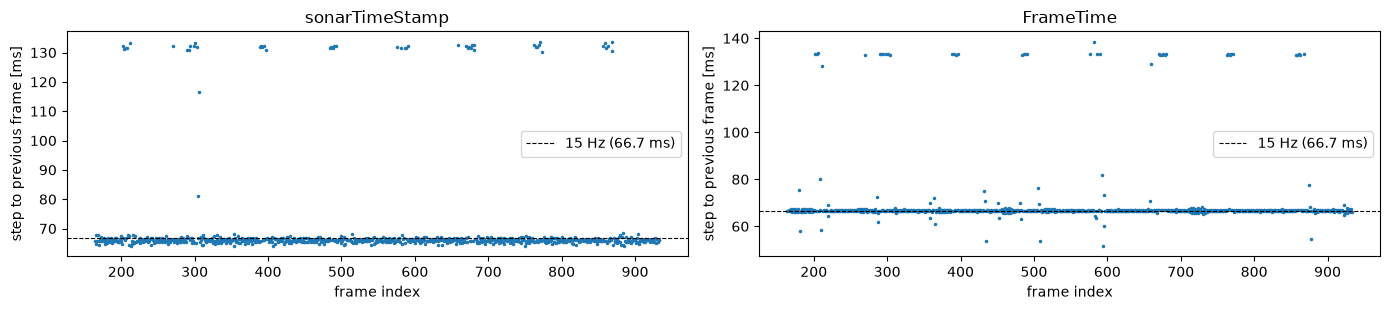

In [9]:
CLOCKS = ("sonarTimeStamp", "FrameTime")
t = pd.DataFrame({c: meta.loc[common, c].to_numpy() * 1e-6 for c in CLOCKS}, index=pd.Index(common, name="frame"))
dt = t.diff().iloc[1:] * 1e3                                             # ms between consecutive frames
gap = dt > 100                                                           # one ping missing on that clock

lag = t.FrameTime - t.sonarTimeStamp
print(f"FrameTime - sonarTimeStamp: {lag.min():.3f} .. {lag.max():.3f} s  (varies by {(lag.max() - lag.min()) * 1e3:.0f} ms)")
for c in CLOCKS:
    print(f"{c:15s} step [ms]: min {dt[c].min():6.1f}  median {dt[c].median():5.1f}  max {dt[c].max():6.1f}"
          f"   steps > 100 ms: {gap[c].sum()}")
print(f"gaps on both clocks: {(gap.sonarTimeStamp & gap.FrameTime).sum()}, "
      f"only sonarTimeStamp: {(gap.sonarTimeStamp & ~gap.FrameTime).sum()}, "
      f"only FrameTime: {(~gap.sonarTimeStamp & gap.FrameTime).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.2))
for a, c in zip(ax, CLOCKS):
    a.plot(dt.index, dt[c], ".", ms=3)
    a.axhline(1e3 / 15, color="k", lw=0.8, ls="--", label="15 Hz (66.7 ms)")
    a.set(title=c, xlabel="frame index", ylabel="step to previous frame [ms]")
    a.legend()
plt.tight_layout()

**How to read this.** On both clocks most steps are ~66 ms, but about one in sixteen is ~133 ms: a ping is
missing while the frame index still goes up by 1. So **frame index is not time**.

The two clocks mostly agree on *where* the gaps are, but not always: some gaps appear only on one clock, a frame
or two apart. `sonarTimeStamp` has two clean levels; `FrameTime` has extra jitter and occasionally a gap
"arrives" a frame later. That is what you expect if `FrameTime` is the time a frame reached the PC: frames are
sent over the network with a varying delay (here the difference between the clocks varies by ~70 ms, about one
frame). The ~0.6 s constant part of that difference says nothing by itself: the two clocks have different zeros.

### 2b. Which clock were the gantry and GoPro matched on?

The gaps give us a free test. Across a gap, twice as much time passes, so the rig moves about twice as far. Take
a step that is a gap on only **one** of the two clocks:

- if the gantry was matched on that clock, the gantry step there is about **2x** normal;
- if it was matched on the other clock, the step there looks **normal**.

We apply the same test to three things:

- the **gantry** step: distance between consecutive `gantry.csv` positions [mm];
- the **pan** step: change of the rotator's pan angle [deg];
- the **GoPro** step: how far consecutive GoPro images shift, measured with *phase correlation*, which finds the
  image shift that best lines up two images (on 480 x 270 grey copies, for speed). This is rough: the camera rotates
  and translates, so near and far parts of the scene shift by different amounts. It is only compared to itself, so
  it doesn't need to be exact.

Rig speed changes along the pass, so each step is divided by the average of the 15 steps around it:
`1.0` = normal, `2.0` = twice as far as its neighbours.

,gantry,pan,GoPro,steps
no gap,1.00,1.04,0.98,716
gap on sonarTimeStamp only,0.84,0.93,0.99,14
gap on FrameTime only,1.65,1.45,1.36,6
gap on both,1.58,1.57,1.52,34


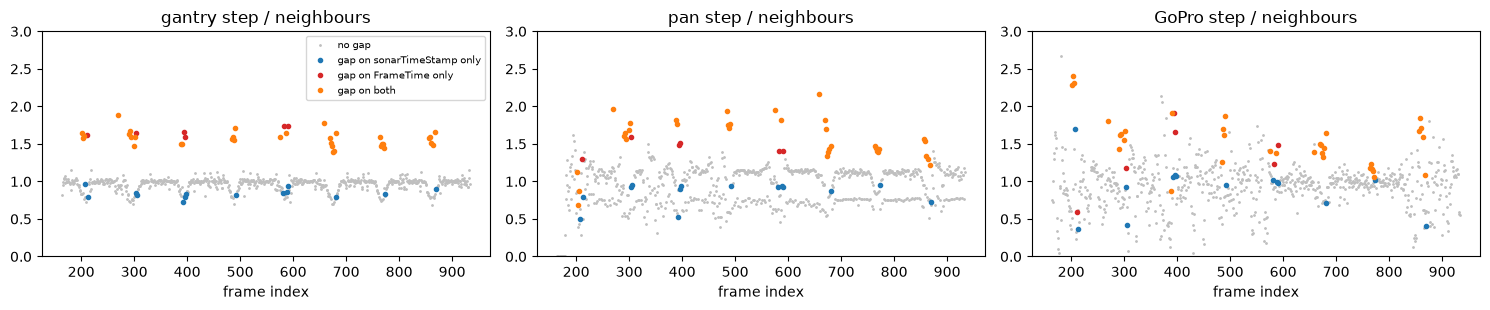

In [10]:
def gopro_grey(i: int) -> np.ndarray:
    im = cv2.imread(str(REC / "gopro" / f"{i:04d}.jpg"), cv2.IMREAD_GRAYSCALE)
    return cv2.resize(im, (480, 270), interpolation=cv2.INTER_AREA).astype(np.float32)


grey = [gopro_grey(i) for i in common]
steps = pd.DataFrame({
    "gantry": np.linalg.norm(np.diff(gantry.loc[common, ["x", "y", "z"]].to_numpy(), axis=0), axis=1) * 1e3,
    "pan": np.abs(np.diff(meta.loc[common, "SonarPan"].to_numpy())),
    "GoPro": [np.hypot(*cv2.phaseCorrelate(a, b)[0]) for a, b in zip(grey[:-1], grey[1:])],
}, index=dt.index)
rel = steps / steps.rolling(15, center=True, min_periods=5).mean()     # step relative to its neighbours

kind = pd.Series("no gap", index=dt.index)
kind[gap.sonarTimeStamp & ~gap.FrameTime] = "gap on sonarTimeStamp only"
kind[~gap.sonarTimeStamp & gap.FrameTime] = "gap on FrameTime only"
kind[gap.sonarTimeStamp & gap.FrameTime] = "gap on both"
order = ["no gap", "gap on sonarTimeStamp only", "gap on FrameTime only", "gap on both"]
table = rel.groupby(kind).median().loc[order].round(2)
table["steps"] = kind.value_counts().loc[order]
display(table)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
colors = {"no gap": "0.75", "gap on sonarTimeStamp only": "C0", "gap on FrameTime only": "C3", "gap on both": "C1"}
for a, col in zip(ax, rel):
    for k in order:
        sel = kind == k
        a.plot(rel.index[sel], rel[col][sel], ".", ms=2 if k == "no gap" else 6, color=colors[k], label=k)
    a.set(title=f"{col} step / neighbours", xlabel="frame index", ylim=(0, 3))
ax[0].legend(fontsize=7)
plt.tight_layout()

**What this shows.** At gaps on `sonarTimeStamp` only, all three steps are normal (0.8–1.0). At gaps on
`FrameTime` only, and on both, they are clearly larger (1.4–1.65). Below the ideal 2 because the gaps come in
clusters, so the neighbours used for the comparison often include a gap themselves. So the gantry positions, the pan angles and
the GoPro images were all matched on **`FrameTime`**, the PC's clock. What matters is that the GoPro splits the same way as the gantry.

**What this means for the poses.**

- Everything in the dataset is consistent with *one* clock, `FrameTime`. That's good: within a frame, the sonar
  image, gantry position, pan and GoPro image all belong together *as the PC saw them*.
- But the sonar *pinged* at `sonarTimeStamp`. `FrameTime` is that moment plus a network delay, and the delay
  varies by about one frame (~70 ms ≈ 3.5 mm of gantry motion and ~0.2° of pan). So the sonar's pose
  can be off by up to about one frame's worth of motion, varying from frame to frame.
- A **constant** delay (the same for every frame), or a constant offset of the whole GoPro clip, does not show
  up in this test at all. Step 3 checks that by projecting the target into the GoPro images.

> **Decision: the timing jitter is *not* corrected.** All values are used exactly as matched by the dataset
> authors, on `FrameTime`. The sonar frames therefore carry a pose error of up to about one frame's worth of
> motion (~3.5 mm, ~0.2° pan), varying from frame to frame. That is about one sonar range row (3 mm).
>
> *Why:* it is small next to other known pose uncertainties of this dataset (a few degrees of camera
> mount orientation, centimetre-level range offsets), and correcting it adds a modelling step of our own.
>
> *How it could be corrected, if later steps show jittery sonar residuals:* treat `sonarTimeStamp` as the true
> moment of each ping, and interpolate the gantry positions and pan angles (which are known at `FrameTime`) to
> `sonarTimeStamp + c`, where `c` is the average `FrameTime - sonarTimeStamp`. This removes the jitter, but
> not any constant delay. The GoPro images can't be re-timed this way, since only one image per frame was kept.

### 2c. The frame table

The output of this step: one row per frame with everything step 3 needs. `t` is `FrameTime`, in seconds from the
first frame, since that's the clock the data was matched on.

In [11]:
frames = pd.DataFrame({
    "t": t.FrameTime - t.FrameTime.iloc[0],
    "x": gantry.loc[common, "x"], "y": gantry.loc[common, "y"], "z": gantry.loc[common, "z"],
    "pan": meta.loc[common, "SonarPan"], "tilt": meta.loc[common, "SonarTilt"], "roll": meta.loc[common, "SonarRoll"],
    "sonar_file": [f"aris_raw/{i:04d}.pgm" for i in common],
    "gopro_file": [f"gopro/{i:04d}.jpg" for i in common],
}, index=pd.Index(common, name="frame"))
frames

,t,x,y,z,pan,tilt,roll,sonar_file,gopro_file
frame,,,,,,,,,
163,0.000000,0.165309,0.992926,-0.75,165.000000,-22.0,-0.0,aris_raw/0163.pgm,gopro/0163.jpg
164,0.066668,0.165435,0.990295,-0.75,165.000000,-22.0,-0.0,aris_raw/0164.pgm,gopro/0164.jpg
165,0.133291,0.165581,0.987222,-0.75,165.000000,-22.0,-0.0,aris_raw/0165.pgm,gopro/0165.jpg
166,0.200283,0.165736,0.984024,-0.75,165.000000,-22.0,-0.0,aris_raw/0166.pgm,gopro/0166.jpg
167,0.266764,0.165906,0.980674,-0.75,164.999832,-22.0,-0.0,aris_raw/0167.pgm,gopro/0167.jpg
...,...,...,...,...,...,...,...,...,...
929,53.733570,2.198772,0.964736,-0.75,19.668167,-22.0,-0.0,aris_raw/0929.pgm,gopro/0929.jpg
930,53.799482,2.198942,0.967802,-0.75,19.510500,-22.0,-0.0,aris_raw/0930.pgm,gopro/0930.jpg
931,53.866090,2.199151,0.971622,-0.75,19.398834,-22.0,-0.0,aris_raw/0931.pgm,gopro/0931.jpg


## Step 3: poses

The background section explained what a pose is: `T_world_sensor`, a 4x4 matrix that maps points from the
sensor's frame into the world. Nothing in the dataset measures the sensor poses directly. We build them by
**chaining** transforms, each from a source we can name:

```
world ──(gantry.csv x,y,z)──▶ crane ──(fixed offset + pan/tilt/roll)──▶ ar3 ──┬──(fixed)──▶ aris ──(fixed)──▶ sonar
                                                                              └──(fixed, 3 links)───────────▶ camera
```

| Link | Source | Changes per frame? |
|---|---|---|
| world → crane | `gantry.csv` (x, y, z), translation only | yes |
| crane → ar3 | `transforms.yaml` fixed offset and flip, then the rotator angles from `aris_frame_meta.csv` | yes (pan) |
| ar3 → aris → sonar | `transforms.yaml` | no |
| ar3 → GoPro mount → camera | `transforms.yaml` | no |

**Notation.** `T_a_b` maps coordinates in frame `b` to frame `a`. Transforms chain by matching the inner
names: `T_a_c = T_a_b · T_b_c`. So `T_world_sonar = T_world_crane · T_crane_ar3 · T_ar3_aris · T_aris_sonar`.

### 3a. The fixed links: `calibration/transforms.yaml`

Each entry gives a child frame's position (`translation`, metres) and orientation (`rotation`, a quaternion
x, y, z, w) in its parent frame. In matrix form that is `T_parent_child`. The cell below prints each link of
the rig as a 4x4 matrix. The rotation part's **columns** are the child's x, y, z axes written in the parent's axes.

In [12]:
import json
from scipy.spatial.transform import Rotation

TF = {e["frame_id"]: e for part in yaml.safe_load((DATA_ROOT / "calibration" / "transforms.yaml").read_text()).values()
      for e in part}

# recording folder -> target frame in transforms.yaml (folder names and frame names differ)
TARGET_FRAMES = {
    "100lbs_bomb": "target/100lbs",
    "100lbs_bomb_(floor)": "target/100lbs_floor",
    "15cm_mortar": "target/mortar_shell",
    "20lbs_incendiary": "target/incendiary",
    "test_cylinder": "target/cylinder",
}


def link(frame: str) -> np.ndarray:
    # 4x4 transform of one transforms.yaml entry: maps coordinates in `frame` into its parent frame
    e, T = TF[frame], np.eye(4)
    q, t = e["rotation"], e["translation"]
    T[:3, :3] = Rotation.from_quat([q["x"], q["y"], q["z"], q["w"]]).as_matrix()   # scipy order: x, y, z, w
    T[:3, 3] = [t["x"], t["y"], t["z"]]
    return T


def chain(frame: str, root: str) -> np.ndarray:
    # multiply the links from `frame` up to `root`: T_root_frame = T_root_a @ T_a_b @ ... @ T_z_frame
    T = np.eye(4)
    while frame != root:
        T = link(frame) @ T
        frame = TF[frame]["parent_frame_id"]
    return T


for f in ("setup/ar3", "setup/aris", "setup/sonar", "setup/gopro_mounting_hole", "setup/gopro_mounting_axis", "setup/camera"):
    print(f"{f}  (parent: {TF[f]['parent_frame_id']})\n{np.array2string(link(f), precision=4, suppress_small=True)}\n")

T_ar3_sonar, T_ar3_camera = chain("setup/sonar", "setup/ar3"), chain("setup/camera", "setup/ar3")
d = T_ar3_camera[:3, 3] - T_ar3_sonar[:3, 3]
print(f"camera relative to sonar, in sonar axes (x right, y down, z forward) [m]: {T_ar3_sonar[:3, :3].T @ d}")
print(f"angle between camera and sonar orientation [deg]: "
      f"{np.degrees(Rotation.from_matrix(T_ar3_sonar[:3, :3].T @ T_ar3_camera[:3, :3]).magnitude()):.2f}")

setup/ar3  (parent: setup/portal_crane)
[[-1.     0.     0.     0.   ]
 [ 0.     1.     0.     0.174]
 [ 0.     0.    -1.    -0.338]
 [ 0.     0.     0.     1.   ]]

setup/aris  (parent: setup/ar3)
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

setup/sonar  (parent: setup/aris)
[[ 0.      0.      1.     -0.1087]
 [ 1.      0.      0.      0.    ]
 [ 0.      1.      0.      0.    ]
 [ 0.      0.      0.      1.    ]]

setup/gopro_mounting_hole  (parent: setup/ar3)
[[ 1.      0.      0.      0.1265]
 [ 0.      1.      0.      0.023 ]
 [ 0.      0.      1.     -0.1055]
 [ 0.      0.      0.      1.    ]]

setup/gopro_mounting_axis  (parent: setup/gopro_mounting_hole)
[[ 1.      0.      0.      0.0213]
 [ 0.      1.      0.      0.    ]
 [ 0.      0.      1.     -0.0075]
 [ 0.      0.      0.      1.    ]]

setup/camera  (parent: setup/gopro_mounting_axis)
[[ 0.      0.      1.      0.0192]
 [ 1.      0.      0.     -0.0195]
 [ 0.      1.      0.     -0.0415]
 [ 0.      0.  

**How to read the links**

- **`setup/ar3`**: the rotation `diag(-1, 1, -1)` is 180° about y: the rotator hangs **upside down** from the
  crane, so its z axis points down. It sits 0.174 m along y and 0.338 m below the crane's reference point.
- **`setup/aris`**: identity, so the sonar housing frame is the rotator frame. Its x axis is the viewing
  direction (at zero pan/tilt/roll).
- **`setup/sonar`**: the rotation matrix has columns (0,1,0), (0,0,1), (1,0,0). That is not a physical rotation,
  only a **relabelling**: sonar x = aris y (right), sonar y = aris z (down), sonar z = aris x (forward). It puts the
  sensor in the x right, y down, z forward convention. The −0.109 m shift is along the viewing direction: the
  sonar's reference point is 10.9 cm *behind* the rotator axis.
- **GoPro**: three offsets (mounting hole → mounting axis → lens), then the same relabelling. In `transforms.yaml`
  the mount has commented-out rotations (10° about z, −4° about y): the authors weren't sure the GoPro is
  perfectly straight. We use the file as it is.

**Result:** in the calibration, the camera sits 27.6 cm in front of the sonar, 15.5 cm above it (y down, so −0.155
is up) and 0.35 cm to the right, with **exactly the same orientation**. That's an assumption of the calibration file,
not a measurement. Comparing with COLMAP earlier suggested the real camera orientation is off by a few degrees.

### 3b. The moving links, and the poses for every frame

Two links change every frame:

- **world → crane**: a pure translation by the gantry position (x, y, z). The crane runs on rails, it doesn't
  rotate.
- **the rotator angles**: `Rot = Rz(pan) · Ry(tilt) · Rx(roll)`, in the rotator's own (upside-down) axes. Because
  ar3 is flipped, its z axis is vertical (pan turns around the vertical), y is sideways (tilt nods up and down) and
  x is the viewing direction (roll spins around it). The order matters, because rotations don't commute: tilting
  by −22° and then panning by 95° is not the same as the reverse. The order isn't documented in the dataset. We use
  the authors' own (`demo/transforms_nb.ipynb`, scipy `from_euler("xyz", [roll, tilt, pan])`), and 3c/3d test it.

Together:

```
T_world_sensor = T_world_crane(x, y, z) · T_crane_ar3 · Rot(roll, tilt, pan) · T_ar3_sensor
                 └ per frame ┘           └ fixed ┘   └ per frame ┘          └ fixed (3a) ┘
```

The table shows the resulting poses for the first, middle and last frame. For each pose it gives the position,
how far the viewing direction points down, the distance to the target origin (from `transforms.yaml`), and how
far the target is from the viewing direction.

In [13]:
def rotator(roll, tilt, pan) -> np.ndarray:
    # (N, 4, 4) rotation of the AR3: roll about x, then tilt about y, then pan about z (fixed axes) = Rz Ry Rx
    T = np.tile(np.eye(4), (len(pan), 1, 1))
    T[:, :3, :3] = Rotation.from_euler("xyz", np.stack([roll, tilt, pan], -1), degrees=True).as_matrix()
    return T


N = len(frames)
T_world_crane = np.tile(np.eye(4), (N, 1, 1))
T_world_crane[:, :3, 3] = frames[["x", "y", "z"]].to_numpy()                    # gantry: translation only
T_world_ar3 = T_world_crane @ link("setup/ar3") @ rotator(*frames[["roll", "tilt", "pan"]].to_numpy().T)
T_world_sonar = T_world_ar3 @ T_ar3_sonar                                       # (N, 4, 4)
T_world_camera = T_world_ar3 @ T_ar3_camera                                     # (N, 4, 4)

target = chain(TARGET_FRAMES[TARGET], "world")[:3, 3]
print(f"target origin ({TARGET_FRAMES[TARGET]}) in world [m]: {target}")


def summary(T: np.ndarray) -> pd.DataFrame:
    pos, fwd = T[:, :3, 3], T[:, :3, 2]                                          # column 2 = sensor z = viewing direction
    to_t = target - pos
    d = np.linalg.norm(to_t, axis=1)
    return pd.DataFrame({
        "x": pos[:, 0], "y": pos[:, 1], "z": pos[:, 2],
        "looks down [deg]": np.degrees(np.arcsin(-fwd[:, 2])),
        "distance to target [m]": d,
        "target off-axis [deg]": np.degrees(np.arccos(np.einsum("ij,ij->i", fwd, to_t) / d)),
    }, index=frames.index)


show = [frames.index[0], frames.index[len(frames) // 2], frames.index[-1]]
display(pd.concat({"sonar": summary(T_world_sonar).loc[show], "camera": summary(T_world_camera).loc[show]}).round(3))

target origin (target/incendiary) in world [m]: [ 1.2351    1.409233 -1.530784]


x      y      z  looks down [deg]  distance to target [m]  \
       frame                                                                  
sonar  163    0.068  1.141 -1.047              22.0                   1.292   
       548    1.172  0.374 -1.047              22.0                   1.145   
       933    2.295  1.119 -1.047              22.0                   1.200   
camera 163    0.372  1.219 -1.007              22.0                   1.028   
       548    1.203  0.686 -1.007              22.0                   0.894   
       933    2.000  1.225 -1.007              22.0                   0.945   

              target off-axis [deg]  
       frame                         
sonar  163                    1.900  
       548                    3.299  
       933                    3.885  
camera 163                    8.923  
       548                   14.026  
       933                   12.625

**How to read this**

- **Looks down 22.0°** for both sensors: exactly the tilt setting, as it should be.
- **The sonar distance is an independent check.** At frame 548 the chain puts the sonar 1.145 m from the target
  origin. In step 1d the bright arc in that frame's sonar image was at ~1.15 m. The pose uses only gantry, rotator
  and calibration data, never the sonar image, so this agreement is a real test. Expect agreement within a few cm,
  not mm: the target origin is a reference point on the target, not the surface that echoes.
- **Off-axis:** the sonar points almost straight at the target (2–4°). The camera sees it 9–14° off its centre,
  because it sits 28 cm in front and 15 cm above the sonar while pointing in the same direction.

### 3c. Top view of the pass

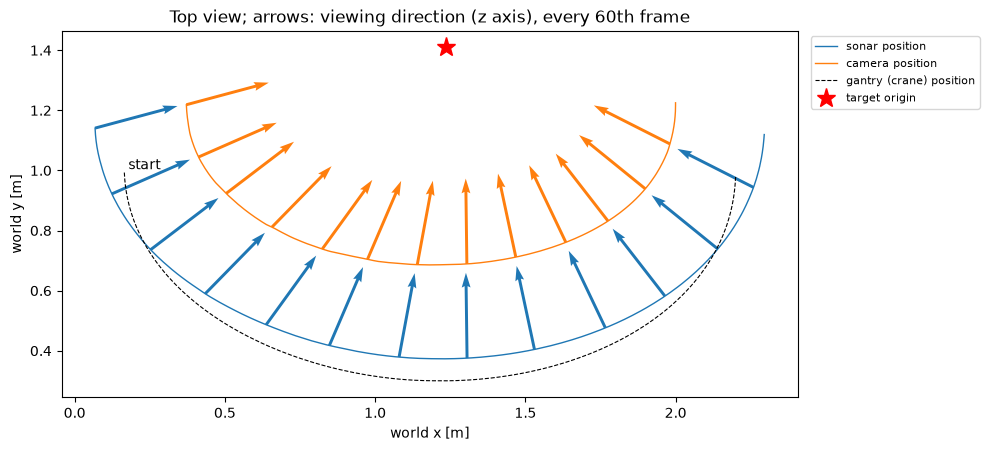

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
for T, name, col in ((T_world_sonar, "sonar", "C0"), (T_world_camera, "camera", "C1")):
    p, f = T[:, :3, 3], T[:, :3, 2]                     # position, viewing direction (sensor z axis)
    ax.plot(p[:, 0], p[:, 1], color=col, lw=1, label=f"{name} position")
    k = slice(None, None, 60)
    ax.quiver(p[k, 0], p[k, 1], f[k, 0], f[k, 1], color=col, angles="xy", scale=8, width=0.004)
ax.plot(frames.x, frames.y, "k--", lw=0.8, label="gantry (crane) position")
ax.plot(*target[:2], "r*", ms=14, label="target origin")
ax.text(frames.x.iloc[0], frames.y.iloc[0], " start", va="bottom")
ax.set(xlabel="world x [m]", ylabel="world y [m]", aspect="equal",
       title="Top view; arrows: viewing direction (z axis), every 60th frame")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()

**How to read this.** The "L to R" pass is a **half circle around the target** at constant height, not a
straight line. The pan turns so that both sensors keep pointing at the target. The camera path lies inside the
sonar path because the camera sits in front of the sonar, closer to the target. All arrows converge on the
target, which confirms the rotation order and the pan sign: with the pan sign flipped, the arrows would point away.

### 3d. Check: does the target land where the authors labelled it?

This is the check that step 2 deferred: a constant time offset, or a wrong camera mount, would put the target in the
wrong place in the image. The authors drew a bounding box around the target in every GoPro image
(`labels/NNNN.json`, in 640 x 360 pixels, so x3 for the 1920 x 1080 frames). The pose gives us another prediction
of where the target should be:

1. move the target origin from world into camera coordinates with the inverse pose: `p_cam = T_world_camera⁻¹ · p_world`;
2. project it into the image with the fisheye camera model from step 1 (`cv2.fisheye.projectPoints`).

If the poses are right, the projected point falls inside the box in every frame.

projected target origin inside the label box: 100% of 771 frames
offset from box centre [px]: x median -74 (range -130..+37), y median +38 (range -6..+69)
box size [px]: 465 x 297;  1 deg at the image centre ≈ 23 px


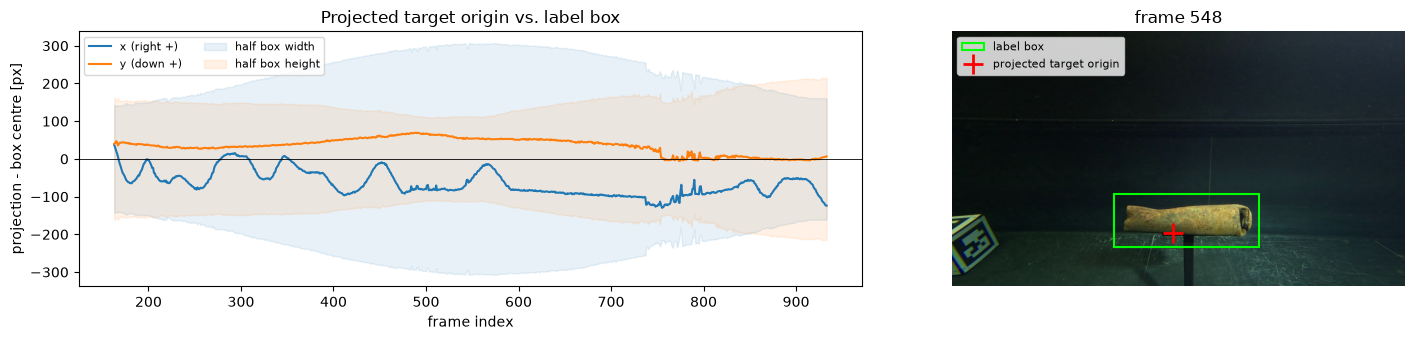

In [15]:
LABEL_SCALE = 1920 / 640          # labels are in 640 x 360 pixels, GoPro frames in 1920 x 1080


def load_box(i: int) -> np.ndarray:
    b = json.loads((REC / "labels" / f"{i:04d}.json").read_text())
    return np.array([b["x_min"], b["y_min"], b["x_max"], b["y_max"]], float) * LABEL_SCALE


boxes = np.array([load_box(i) for i in frames.index])                                  # (N, 4) in 1920 x 1080 px

# target origin in each camera frame (inverse pose), then through the fisheye camera model from step 1
p_cam = np.einsum("nij,j->ni", np.linalg.inv(T_world_camera), np.append(target, 1))[:, :3]
assert (p_cam[:, 2] > 0).all(), "target behind the camera"
uv = cv2.fisheye.projectPoints(p_cam[:, None], np.zeros(3), np.zeros(3), K, dist)[0][:, 0]

centre = (boxes[:, :2] + boxes[:, 2:]) / 2
err = uv - centre                                                                      # px, + = right / down
inside = (uv >= boxes[:, :2]).all(1) & (uv <= boxes[:, 2:]).all(1)
size = boxes[:, 2:] - boxes[:, :2]
print(f"projected target origin inside the label box: {inside.mean():.0%} of {len(inside)} frames")
print(f"offset from box centre [px]: x median {np.median(err[:, 0]):+.0f} (range {err[:, 0].min():+.0f}..{err[:, 0].max():+.0f}), "
      f"y median {np.median(err[:, 1]):+.0f} (range {err[:, 1].min():+.0f}..{err[:, 1].max():+.0f})")
print(f"box size [px]: {np.median(size[:, 0]):.0f} x {np.median(size[:, 1]):.0f};  "
      f"1 deg at the image centre ≈ {K[0, 0] * np.tan(np.radians(1)):.0f} px")

fig, ax = plt.subplots(1, 2, figsize=(15, 3.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax[0].plot(frames.index, err[:, 0], label="x (right +)")
ax[0].plot(frames.index, err[:, 1], label="y (down +)")
ax[0].fill_between(frames.index, -size[:, 0] / 2, size[:, 0] / 2, color="C0", alpha=0.1, label="half box width")
ax[0].fill_between(frames.index, -size[:, 1] / 2, size[:, 1] / 2, color="C1", alpha=0.1, label="half box height")
ax[0].axhline(0, color="k", lw=0.6)
ax[0].set(xlabel="frame index", ylabel="projection - box centre [px]", title="Projected target origin vs. label box")
ax[0].legend(fontsize=8, ncol=2)
j = len(frames) // 2
img = cv2.cvtColor(cv2.imread(str(REC / frames.gopro_file.iloc[j])), cv2.COLOR_BGR2RGB)
ax[1].imshow(img)
x0, y0, x1, y1 = boxes[j]
ax[1].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=1.5, label="label box"))
ax[1].plot(*uv[j], "r+", ms=14, mew=2, label="projected target origin")
ax[1].set(title=f"frame {frames.index[j]}")
ax[1].axis("off")
ax[1].legend(fontsize=8, loc="upper left")
plt.tight_layout()

**What this shows**

- **The projection lands on the target in every frame** (100% inside the box). The red cross sits on the stand,
  just below the casing, rather than in the middle of the box. So the target origin in `transforms.yaml` seems to
  be the mounting point, not the casing centre. That's my reading of the image: the file doesn't say what the
  origin is. That's also why the median offset from the box centre (x ≈ −74 px ≈ 3°, y ≈ +38 px ≈ 1.6°) is not a
  pose error by itself.
- **What this rules out:** a pose error larger than the box. Half a box is ~230 px (≈ 10°) horizontally and
  ~150 px (≈ 6°) vertically. A wrong rotation order, a flipped pan sign, a GoPro clip shifted by seconds, or a
  wrong camera mount would all push the cross out of the box in at least part of the pass.
- **What this cannot rule out:** errors of a few degrees. The ~7° camera orientation error found earlier by
  comparing with COLMAP is within the box, so this test neither confirms nor excludes it. A sharper test needs
  points we know exactly. Step 5 does that for the sonar: is the bright arc at the range and bearing the pose
  predicts?
- **The wiggles** (±60 px ≈ ±2.5°, roughly every 60 frames) and the jumpier curve after frame ~750 come either
  from the label boxes or from the poses. This test can't tell which.

### Step 3 summary

- `T_world_camera`, `T_world_sonar`: `(771, 4, 4)` poses, sensor axes x right, y down, z forward, world = the tank
  frame (z up, metres). These go to Z-Splat in step 6, after converting to its conventions.
- The chain uses the authors' calibration file unchanged: no mount corrections of our own.
- Checks passed: the sensors look down at the tilt angle, the sonar-to-target distance matches the bright arc in
  the sonar image (1.145 m vs. ~1.15 m at frame 548), the viewing directions converge on the target, and the
  projected target lies inside the authors' label box in all frames.
- Known limit: the camera orientation is only checked to within a few degrees.

## Step 4: camera model

**Why this step is needed.** 3DGS draws each Gaussian by projecting it with a **pinhole camera**: every ray
goes in a straight line through one projection centre onto a flat image. A real lens bends the rays (step 1c
measured shifts of up to 21 px). So we resample the images so they look as if an ideal pinhole camera had taken
them: **undistortion**.

Z-Splat adds a stricter requirement. Its projection (`utils/graphics_utils.py`, `getProjectionMatrix`) uses only
`FovX` and `FovY`, and sets `left = -right`, `top = -bottom`. So it assumes the **principal point is exactly the
image centre**:

| | calibration (`wide`) | Z-Splat assumes |
|---|---|---|
| cx, cy [px] | 980.4, 531.3 | 960, 540 |
| offset | +20.4, −8.7 px (≈ 0.9°, 0.4°) | 0 |

Ignoring that offset would turn every camera view by about 0.9° sideways and 0.4° vertically. So the undistortion
also moves the principal point to the centre. Both happen in one resampling (4b).

### 4a. Which calibration fits? The straight-line test

A pinhole camera maps straight lines in the world to straight lines in the image. A lens with distortion bends
them. So: take long straight edges in an image, undistort points along them with each of the four GoPro
calibrations, and measure how much they still **bow**: how far the middle of the edge lies from the straight line
between its ends, in pixels. The right calibration should give the straightest edges.

The tank has two long straight edges: the line along the back wall (row ~380) and the floor edge (row ~850).
`EDGE_ROWS` gives the row band to search for each one. They were picked by eye for this recording, in a frame
looking straight at the wall. Other recordings may need other rows or another `LINE_FRAME`.

In [16]:
CAMERA_MODES = {p.stem.removeprefix("camera_parameter_"): load_intrinsics(p)
                for p in sorted((DATA_ROOT / "calibration" / "camera_parameters").glob("*.txt"))}

LINE_FRAME = FRAME                                               # needs a frame looking straight at the tank wall
EDGE_ROWS = {"wall line": (340, 420), "floor edge": (820, 900)}  # raw-image row band of each edge, picked by eye (4c)


def edge_points(grey: np.ndarray, rows: tuple[int, int], step: int = 10) -> np.ndarray:
    # (n, 2) points (x, y) along the strongest horizontal edge in a row band: per column, the row of maximum
    # vertical gradient, refined to sub-pixel with a parabola through the peak and its two neighbours
    y0, y1 = rows
    g = np.abs(cv2.Sobel(cv2.GaussianBlur(grey.astype(float), (5, 5), 0), cv2.CV_64F, 0, 1, ksize=5))[y0:y1]
    xs = np.arange(20, grey.shape[1] - 20, step)
    i = np.clip(g[:, xs].argmax(0), 1, y1 - y0 - 2)
    a, b, c = g[i - 1, xs], g[i, xs], g[i + 1, xs]
    return np.stack([xs, y0 + i + 0.5 * (a - c) / (a - 2 * b + c)], 1)


def bow(p: np.ndarray) -> float:
    # how far the middle of the edge lies from the straight chord between its ends [px]; 0 = straight,
    # + = the middle sags downward. Fit a parabola, drop outliers (> 3 x median deviation), fit again.
    keep = np.ones(len(p), bool)
    for _ in range(2):
        q = np.polyfit(p[keep, 0], p[keep, 1], 2)
        res = np.abs(p[:, 1] - np.polyval(q, p[:, 0]))
        keep = res <= 3 * np.median(res) + 0.5
    x0, x1 = p[keep, 0].min(), p[keep, 0].max()
    return np.polyval(q, (x0 + x1) / 2) - (np.polyval(q, x0) + np.polyval(q, x1)) / 2


grey_line = cv2.imread(str(REC / "gopro" / f"{LINE_FRAME:04d}.jpg"), cv2.IMREAD_GRAYSCALE)
edges = {name: edge_points(grey_line, rows) for name, rows in EDGE_ROWS.items()}

rows = {}
for name, p in edges.items():
    rows[name] = {"raw image": bow(p)}
    for mode, (Km, dm) in CAMERA_MODES.items():
        # undistort the edge points with this calibration; x f to express the bow in pixels again
        rows[name][mode] = bow(cv2.fisheye.undistortPoints(p[None], Km, dm)[0] * Km[0, 0])
print(f"bow of straight tank edges in frame {LINE_FRAME} [px], after undistorting with each calibration:")
pd.DataFrame(rows).T.round(1)

bow of straight tank edges in frame 548 [px], after undistorting with each calibration:


,raw image,linear,narrow,superview,wide
wall line,6.4,-21.4,-9.0,7.4,8.8
floor edge,-1.3,49.8,26.8,64.0,-3.3


**How to read this**

- `linear`, `narrow` and `superview` bend the floor edge by 27–64 px: clearly the wrong calibration for this footage.
- `wide` leaves both edges within a few pixels of straight. That's consistent, but weaker evidence than it looks:
  in this frame the edges are nearly straight **even in the raw image**. The wide lens barely moves pixels
  vertically at the ends of these lines (step 1c: the shift is only ~4 px at 1050 px from the centre). So this test
  rules out the other three calibrations, but it can't show how accurate `wide` is. The ~6–9 px bow of the wall
  line in every plausible case is probably the line itself (the detector follows the edge of a dark band that may
  not be perfectly straight), not the lens.
- Conclusion: `wide`, as used since step 1.

### 4b. Undistort to a centred pinhole camera

Three choices define the pinhole camera that Z-Splat will get:

1. **Focal length**: keep fx, fy from the calibration. A pixel near the centre then still covers the same angle, so
   the image keeps its resolution.
2. **Principal point**: exactly at the image centre, as Z-Splat assumes.
3. **Size**: moving the principal point leaves some output pixels with no raw pixel behind them (they'd be black).
   We crop to the largest rectangle, centred on the centre, that has only valid pixels (option A).

**How the resampling works: backwards.** We don't push raw pixels into the new image (that leaves holes and
overlaps). Instead, for every *new* pixel we ask which raw pixel it should come from:

```
for every pixel (u, v) of the NEW image:
    ray    = K_new⁻¹ · (u, v, 1)       the direction this pixel looks in
    (x, y) = fisheye(K, dist, ray)     where the real lens put that direction in the raw image
    new[v, u] = raw[y, x]              bilinear interpolation between the 4 nearest raw pixels
```

`cv2.fisheye.initUndistortRectifyMap` computes `(x, y)` for every new pixel once (`map_x`, `map_y`), and
`cv2.remap` applies it to each image.

In [17]:
# 1. The ideal pinhole camera: same focal lengths, principal point at the centre of a W x H image
K_full = np.array([[K[0, 0], 0, W / 2], [0, K[1, 1], H / 2], [0, 0, 1]])

# 2. Where does the raw image's border land in that pinhole image? Inside that outline every pixel has a raw
#    pixel behind it; outside it would be black. Take the largest rectangle centred on the image centre.
s = np.linspace(0, 1, 500)[:, None]
border = {"top": np.hstack([s * (W - 1), 0 * s]), "bottom": np.hstack([s * (W - 1), 0 * s + H - 1]),
          "left": np.hstack([0 * s, s * (H - 1)]), "right": np.hstack([0 * s + W - 1, s * (H - 1)])}
b = {k: cv2.fisheye.undistortPoints(v[None], K, dist, P=K_full)[0] for k, v in border.items()}
half_w = min(W / 2 - b["left"][:, 0].max(), b["right"][:, 0].min() - W / 2)
half_h = min(H / 2 - b["top"][:, 1].max(), b["bottom"][:, 1].min() - H / 2)
W_new, H_new = 2 * int(half_w - 1), 2 * int(half_h - 1)          # 1 px safety margin, even size

# 3. The final pinhole camera: principal point at the centre of the cropped image
K_new = np.array([[K[0, 0], 0, W_new / 2], [0, K[1, 1], H_new / 2], [0, 0, 1]])
FovX, FovY = 2 * np.arctan(W_new / 2 / K_new[0, 0]), 2 * np.arctan(H_new / 2 / K_new[1, 1])

# 4. The resampling map: for every output pixel (u, v), the raw pixel (map_x, map_y) it is taken from
map_x, map_y = cv2.fisheye.initUndistortRectifyMap(K, dist, np.eye(3), K_new, (W_new, H_new), cv2.CV_32FC1)


def undistort(img: np.ndarray) -> np.ndarray:
    return cv2.remap(img, map_x, map_y, interpolation=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)


assert map_x.min() >= 0 and map_x.max() <= W - 1 and map_y.min() >= 0 and map_y.max() <= H - 1, "output pixel outside raw image"
print(f"black strips if the size were kept: left {b['left'][:, 0].max():.1f}, right {W - b['right'][:, 0].min():.1f}, "
      f"top {b['top'][:, 1].max():.1f}, bottom {H - b['bottom'][:, 1].min():.1f} px")
print(f"undistorted image: {W_new} x {H_new} px (raw {W} x {H})")
print(f"K_new: fx {K_new[0, 0]:.1f}, fy {K_new[1, 1]:.1f}, cx {K_new[0, 2]:.1f}, cy {K_new[1, 2]:.1f}")
print(f"FovX {np.degrees(FovX):.2f} deg, FovY {np.degrees(FovY):.2f} deg")
print(f"sampled raw area: x {map_x.min():.1f}..{map_x.max():.1f}, y {map_y.min():.1f}..{map_y.max():.1f}  (all inside the raw image)")

black strips if the size were kept: left -2.2, right 31.6, top 17.6, bottom 2.5 px
undistorted image: 1854 x 1042 px (raw 1920 x 1080)
K_new: fx 1312.4, fy 1312.6, cx 927.0, cy 521.0
FovX 70.47 deg, FovY 43.30 deg
sampled raw area: x 46.1..1913.6, y 6.2..1055.4  (all inside the raw image)


**How to read this**

- **Black strips:** if we kept 1920 x 1080, there would be a ~32 px black strip on the right and ~18 px at the top.
  On the left and bottom the raw image reaches (just) far enough: a negative value means it extends beyond the
  border. The strips are lopsided because the principal point is off-centre (right of and above the image centre).
- **The pinhole camera for Z-Splat:** 1854 x 1042 px, the same focal lengths, the principal point exactly at the
  centre, FovX x FovY = 70.5° x 43.3°. For comparison, the raw image covers ~72.9° x 45.5° (step 1c), so the
  crop costs about 1° on each side.
- **Every output pixel** samples from inside the raw image (the `assert`), so there are no black pixels.
- Bilinear interpolation blurs very slightly (each output pixel is a weighted mix of 4 raw pixels). That is the
  usual cost of undistortion.

### 4c. Check on the image itself

4a undistorted only the detected edge *points*. Here we undistort the whole image and detect the edges again on
the result, to check that `undistort()` does what 4a predicts.

bow measured on the image itself [px]:


,raw,undistorted
wall line,6.4,7.4
floor edge,-1.3,0.7


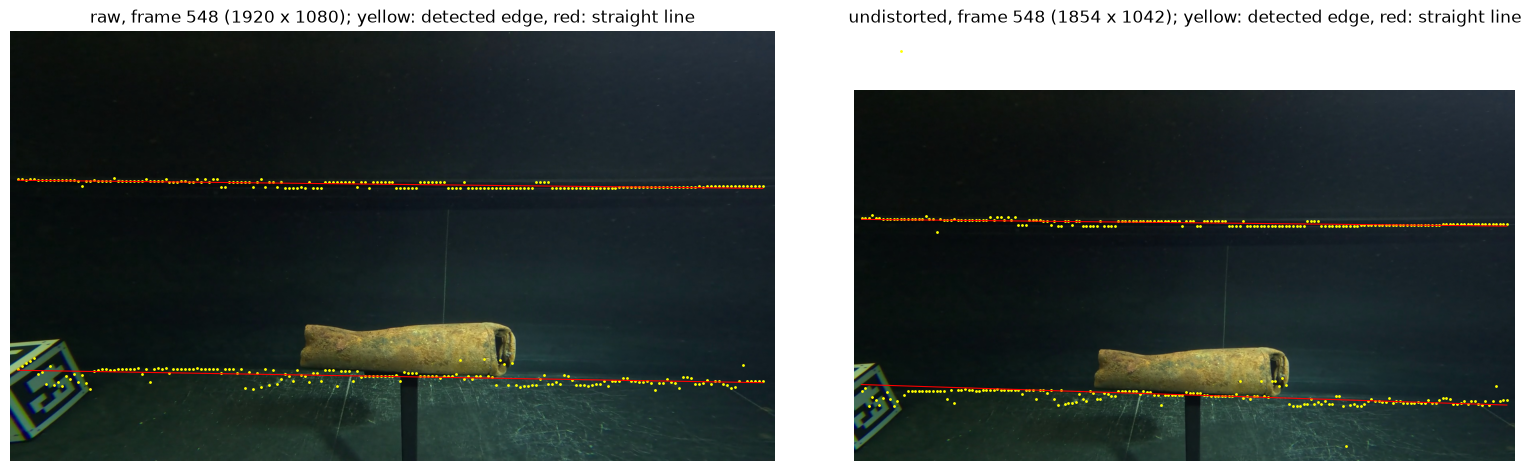

In [18]:
raw = cv2.cvtColor(cv2.imread(str(REC / "gopro" / f"{LINE_FRAME:04d}.jpg")), cv2.COLOR_BGR2RGB)
und = undistort(raw)
grey_und = cv2.cvtColor(und, cv2.COLOR_RGB2GRAY)
shift_rows = K_new[1, 2] - K[1, 2]                     # rows near the centre move by about this much

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
result = {}
for a, img, grey, title, dy in ((ax[0], raw, grey_line, "raw", 0), (ax[1], und, grey_und, "undistorted", shift_rows)):
    a.imshow(img)
    for name, (y0, y1) in EDGE_ROWS.items():
        p = edge_points(grey, (int(y0 + dy), int(y1 + dy)))
        q = np.polyfit(p[:, 0], p[:, 1], 1)                      # straight line through the edge
        a.plot(p[:, 0], p[:, 1], ".", ms=2, color="yellow")
        a.plot(p[[0, -1], 0], np.polyval(q, p[[0, -1], 0]), "r-", lw=0.8)
        result.setdefault(name, {})[title] = bow(p)
    a.set(title=f"{title}, frame {LINE_FRAME} ({img.shape[1]} x {img.shape[0]}); yellow: detected edge, red: straight line")
    a.axis("off")
plt.tight_layout()
print("bow measured on the image itself [px]:")
display(pd.DataFrame(result).T.round(1))

**How to read this.** The undistorted image is slightly smaller, and its content sits a few pixels lower, because
the principal point moved. The edges stay straight to within a few pixels (compare with 4a). The small differences
between 4a and this table (e.g. 8.8 vs. 7.4 px for the wall line) come from detecting the edge again on a resampled
image. They show the noise of this test: about 2 px.

### Step 4 summary

- Calibration: `wide` + fisheye model. The other three calibrations bend straight edges by 20–60 px. How accurate
  `wide` is can't be shown with this test, since the edges in this frame are nearly straight even in the raw image.
- `undistort(img)` turns a raw GoPro frame into an ideal pinhole image of `W_new x H_new` = 1854 x 1042 px, with the
  principal point exactly at the centre, as Z-Splat assumes. Cropped so that no pixel is black (option A).
- `K_new`, `FovX`, `FovY`: the pinhole camera that goes to Z-Splat in step 6.
- Not touched by this step: the camera *pose* (step 3). Undistortion only fixes how the camera maps directions to
  pixels, not where it points.

## Step 5: sonar geometry

A raw ARIS frame is a 441 x 128 grid of echo strengths. To use it we need to know, for each pixel, where in space
it looks:

- **row → range**: from the timing settings (step 1b). Still to check: which end is near.
- **column → bearing** (the horizontal angle): not in the data files, not uniform, and possibly mirrored.
- **elevation**: not measured at all. Each pixel collects echoes from a 15° vertical arc.

Then we translate this into **Z-Splat's sonar model**, which is not the ARIS's native geometry. From the code
(reader `add_sonar`; rasterizer `diff-gs-with-depth`, branch `diff-gs-main-FLS-2`, `cuda_rasterizer/forward.cu`):

```
the sonar is rendered as a small PINHOLE view (W columns x H rows, FovX = hfov, FovY = vfov) from the sonar pose
for every pixel, each Gaussian adds its opacity to a histogram over RANGE   (forward.cu: depth = sqrt(x² + y² + z²))
the histograms of all rows in a column are summed     → elevation is integrated away, like in a real sonar
result: (range bins x W columns), each column scaled to max 1, compared (L1) with the sonar image
```

| | ARIS raw | what we give Z-Splat |
|---|---|---|
| columns | 128 beams, about uniform in **angle**, column 0 = rightmost | 128 pinhole columns, uniform in **tan(angle)**, column 0 = leftmost |
| rows | 441 range bins, ~0.695–2.010 m, near first | the same 441 bins |

**Setup decisions (made before this step):**

- **Rasterizer version.** We use the head of the rasterizer's `diff-gs-main-FLS-2` branch (`c79e907`), not the
  commit the main repo pins (`b4ae7f6`). The pinned commit has 200 range bins over 0–8 m, which doesn't match the
  FLS reader's 512-row sonar images; the branch head has 512 bins over 0.75–3.0 m.
- **Range window.** That 0.75–3.0 m window is hard-coded for the authors' tank. Step 6 sets it to ours
  (`R_MIN`..`R_MAX`, 441 bins), so the sonar images keep their native 3 mm resolution and need no resampling in range.
- **128 columns**, one per beam (the reader's default is 96).

### 5a. Range axis

Row `i` is centred at `R_MIN + (i + 0.5) · Δr`. The window drifts by a fraction of a millimetre during the
recording (sound speed changes slightly), so one fixed window is used: the median.

**Which end is near?** The authors' conversion (`scripts/prep_2_aris_to_polar.py`, `aris_frame_to_polar2`) puts
row 0 at the window start, i.e. near. We check that with the poses from step 3: in every frame, find the bright
arc (the row with the most echo energy above the frame's background level) and compare its range with the
predicted distance from the sonar to the target origin.

range window 0.6949 .. 2.0102 m, 441 bins of 2.983 mm; window drift within the recording: 0.48 mm
row 0 = near (as assumed)  arc range - predicted [cm]: median -9.7, 5..95% -15.0 .. -2.9
row 0 = far                arc range - predicted [cm]: median +39.2, 5..95% +24.2 .. +44.7
target elevation in the sonar frame: -3.0 .. +0.3 deg (aperture ±7.5 deg)


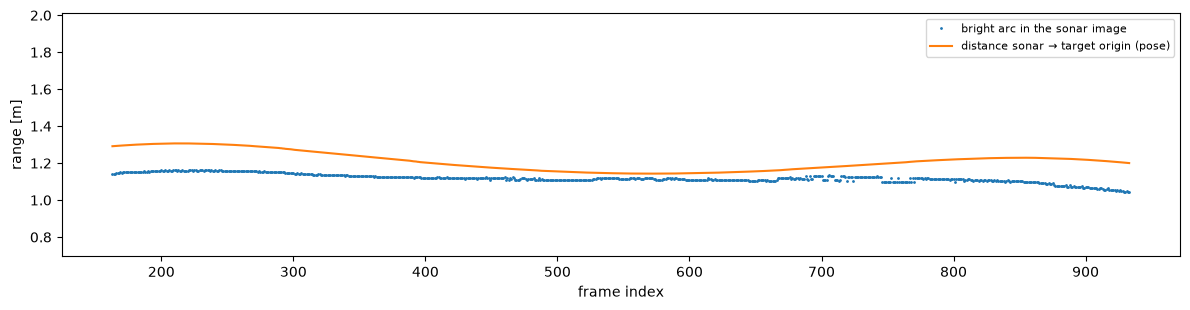

In [19]:
win_start, win_end = meta.loc[common, "WindowStart"], meta.loc[common, "WindowStart"] + meta.loc[common, "WindowLength"]
N_BINS = int(meta.loc[common, "SamplesPerBeam"].iloc[0])
R_MIN, R_MAX = win_start.median(), win_end.median()                      # one fixed window for the whole recording
ranges = R_MIN + (np.arange(N_BINS) + 0.5) * (R_MAX - R_MIN) / N_BINS     # centre of each row [m]
print(f"range window {R_MIN:.4f} .. {R_MAX:.4f} m, {N_BINS} bins of {(R_MAX - R_MIN) / N_BINS * 1e3:.3f} mm; "
      f"window drift within the recording: {max(np.ptp(win_start), np.ptp(win_end)) * 1e3:.2f} mm")

sonar_raw = np.stack([cv2.imread(str(REC / f), cv2.IMREAD_UNCHANGED) for f in frames.sonar_file])   # (N, 441, 128) uint8

# predicted: the target origin in sonar coordinates (x right, y down, z forward)
T_sonar_world = np.linalg.inv(T_world_sonar)
p_son = np.einsum("nij,j->ni", T_sonar_world, np.append(target, 1))[:, :3]
pred_range = np.linalg.norm(p_son, axis=1)
pred_elev = np.degrees(np.arctan2(-p_son[:, 1], np.hypot(p_son[:, 0], p_son[:, 2])))     # + = above the boresight

# measured: the row with the most echo energy above each frame's background level
bg = np.median(sonar_raw, axis=(1, 2), keepdims=True).astype(np.int16)
energy = np.clip(sonar_raw.astype(np.int16) - bg, 0, None).sum(2)        # (N, 441)
arc_range = ranges[energy.argmax(1)]
arc_range_reversed = ranges[::-1][energy.argmax(1)]                     # if row 0 were the FAR end

for name, r in (("row 0 = near (as assumed)", arc_range), ("row 0 = far", arc_range_reversed)):
    res = (r - pred_range) * 100
    print(f"{name:26s} arc range - predicted [cm]: median {np.median(res):+.1f}, "
          f"5..95% {np.percentile(res, 5):+.1f} .. {np.percentile(res, 95):+.1f}")
print(f"target elevation in the sonar frame: {pred_elev.min():+.1f} .. {pred_elev.max():+.1f} deg (aperture ±7.5 deg)")

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(frames.index, arc_range, ".", ms=2, label="bright arc in the sonar image")
ax.plot(frames.index, pred_range, label="distance sonar → target origin (pose)")
ax.set(xlabel="frame index", ylabel="range [m]", ylim=(R_MIN, R_MAX))
ax.legend(fontsize=8)
plt.tight_layout()

**How to read this**

- **Row 0 is the near end.** With rows reversed, the arc would sit ~39 cm farther than the target; as recorded it
  sits ~10 cm *closer*.
- **Why closer, and why the spread?** The bright arc is the casing surface facing the sonar. The target origin is
  the mount point under the casing (step 3d), so the surface is nearer than the origin, and *how much* nearer
  depends on which side of the casing faces the sonar. So this residual does **not** measure a sonar range offset:
  the target origin isn't precise enough for that. (Earlier work using COLMAP points on the casing itself found
  the sonar range off by +1.5…+3 cm.)
- **Elevation:** the target stays within the ±7.5° elevation aperture during the whole pass, so the sonar can
  see it in every frame.

### 5b. Beam angles

The 128 beams are not equally spaced, and their angles are not in the data files. The dataset authors' code has a
table: `scripts/common/aris_definitions.py`, `BeamWidthsAris3000_128` (repository `dfki-ric/uxo-dataset2024`,
commit `323ac6c`). It gives each beam's centre and edges in degrees. The file doesn't say where the numbers come
from; they are probably the manufacturer's (SoundMetrics) beam table. **Confirm the source before citing it.**

The same file maps `PingMode` 9–12 to 128 beams. That's the authors' code, not official documentation, but it
agrees with the 128 columns we see (step 1b).

**Direction.** The authors' conversion to fan images draws beam `k` at angle `−centre[k]` and then mirrors the
image. So raw **column 0 is the rightmost beam**. The check further down tests this against the poses.

beam spacing: 0.230 .. 0.239 deg (mean 0.2364)
total span (outer edges): 30.25 deg
largest difference from equally spaced beams: 0.057 deg


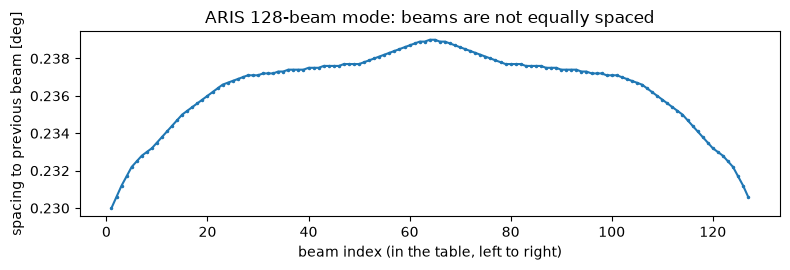

In [20]:
# ARIS Explorer 3000, 128-beam mode: beam centre angles [deg], left to right as seen from the sonar.
# Source: github.com/dfki-ric/uxo-dataset2024 @ 323ac6c, scripts/common/aris_definitions.py, BeamWidthsAris3000_128
# (triplets centre, left edge, right edge; only the centres and the two outer edges are needed here).
BEAM_CENTRES_DEG = np.array([
    -15.0068, -14.7768, -14.5462, -14.3150, -14.0833, -13.8511, -13.6186, -13.3858,
    -13.1528, -12.9196, -12.6861, -12.4523, -12.2182, -11.9838, -11.7491, -11.5141,
    -11.2789, -11.0435, -10.8079, -10.5721, -10.3361, -10.0999,  -9.8635,  -9.6269,
     -9.3902,  -9.1534,  -8.9165,  -8.6795,  -8.4424,  -8.2053,  -7.9682,  -7.7310,
     -7.4938,  -7.2566,  -7.0193,  -6.7820,  -6.5446,  -6.3072,  -6.0698,  -5.8324,
     -5.5949,  -5.3574,  -5.1199,  -4.8823,  -4.6447,  -4.4071,  -4.1695,  -3.9318,
     -3.6941,  -3.4564,  -3.2187,  -2.9809,  -2.7430,  -2.5050,  -2.2669,  -2.0287,
     -1.7904,  -1.5520,  -1.3135,  -1.0749,  -0.8362,  -0.5974,  -0.3585,  -0.1196,
      0.1194,   0.3584,   0.5973,   0.8362,   1.0750,   1.3137,   1.5523,   1.7908,
      2.0292,   2.2675,   2.5057,   2.7438,   2.9818,   3.2197,   3.4575,   3.6952,
      3.9329,   4.1706,   4.4083,   4.6459,   4.8835,   5.1211,   5.3587,   5.5962,
      5.8337,   6.0712,   6.3086,   6.5460,   6.7834,   7.0208,   7.2581,   7.4954,
      7.7326,   7.9698,   8.2070,   8.4441,   8.6812,   8.9183,   9.1553,   9.3922,
      9.6290,   9.8657,  10.1023,  10.3387,  10.5749,  10.8109,  11.0467,  11.2823,
     11.5177,  11.7529,  11.9879,  12.2226,  12.4570,  12.6911,  12.9249,  13.1584,
     13.3916,  13.6246,  13.8574,  14.0899,  14.3221,  14.5538,  14.7850,  15.0156,
])
BEAM_EDGES_DEG = (-15.1218, 15.1306)               # outer edge of the first and of the last beam
assert sonar_raw.shape[2] == len(BEAM_CENTRES_DEG), "this table is for the 128-beam mode"

# Raw column k looks at bearing -centre[k] (+ = right): column 0 is the RIGHTMOST beam
# (authors' prep_2_aris_to_polar.py, aris_frame_to_polar2: beam k drawn at -centre[k], then the image is mirrored).
BEAM_BEARING = -np.radians(BEAM_CENTRES_DEG)

spacing = np.diff(BEAM_CENTRES_DEG)
uniform = np.linspace(BEAM_CENTRES_DEG[0], BEAM_CENTRES_DEG[-1], len(BEAM_CENTRES_DEG))
print(f"beam spacing: {spacing.min():.3f} .. {spacing.max():.3f} deg (mean {spacing.mean():.4f})")
print(f"total span (outer edges): {BEAM_EDGES_DEG[1] - BEAM_EDGES_DEG[0]:.2f} deg")
print(f"largest difference from equally spaced beams: {np.abs(BEAM_CENTRES_DEG - uniform).max():.3f} deg")

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(np.arange(1, 128), spacing, ".-", ms=3)
ax.set(xlabel="beam index (in the table, left to right)", ylabel="spacing to previous beam [deg]",
       title="ARIS 128-beam mode: beams are not equally spaced")
plt.tight_layout()

**How to read this.** The beams are not equally spaced: about 0.239° apart near the centre and 0.230° at the
edges. Treating them as equally spaced would put some beams off by the amount printed above.

**Check: is column 0 really the rightmost beam?** Comparing the arc's centre bearing with the target's predicted
bearing doesn't settle this: the target stays within a few degrees of the centre during the whole pass, so a
mirrored image would look almost the same. We need a prediction whose **sign** flips when the image is mirrored.

The casing gives one. It is a long cylinder lying roughly along world x. Seen at an angle, one end is closer to the
sonar than the other, so its arc in the sonar image is **tilted**: range changes from one side to the other.
Mirroring the columns flips the sign of that tilt.

```
sonar image (bearing across, range down)          same image, columns mirrored
   ‾‾‾‾‾‾‾‾‾‾                                                          ‾‾‾‾‾‾‾‾‾‾
             ‾‾‾‾‾‾‾‾‾‾                                      ‾‾‾‾‾‾‾‾‾‾
                       ‾‾‾‾‾‾‾‾‾‾                  ‾‾‾‾‾‾‾‾‾‾
   range grows to the right: tilt > 0              range grows to the left: tilt < 0
```

The pose predicts the tilt: put the two casing ends at ±`CASING_HALF_LENGTH` along world x from the target origin,
move them into the sonar frame, and divide their range difference by their bearing difference. On the measured
side we fit a line `range = a + tilt · bearing` through the strongest return of each column on the arc.

column 0 = rightmost (authors)   tilt sign agrees with the pose in 78% of 771 frames
column 0 = leftmost (mirrored)   tilt sign agrees with the pose in 22% of 771 frames


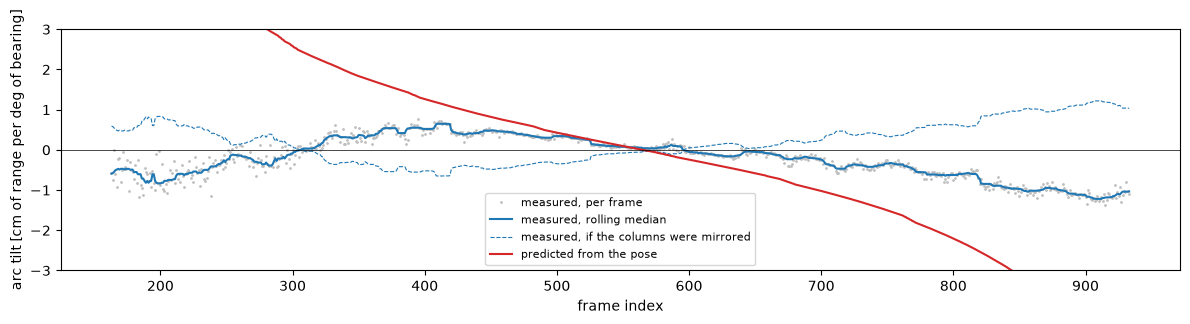

In [21]:
CASING_HALF_LENGTH = 0.20      # m; assumed. The casing lies roughly along world x (seen in the GoPro frames).

# measured: per column, the range of the strongest return; keep clear returns on the arc; fit range = a + tilt * bearing
img = np.clip(sonar_raw.astype(np.int16) - bg, 0, None)          # (N, 441, 128), background removed
row_max, peak = img.argmax(1), img.max(1)                        # (N, 128) each
tilt_meas = np.full(N, np.nan)
for n in range(N):
    ok = (peak[n] > np.percentile(peak[n], 60)) & (np.abs(ranges[row_max[n]] - arc_range[n]) < 0.15)
    if ok.sum() > 15:
        tilt_meas[n] = np.polyfit(BEAM_BEARING[ok], ranges[row_max[n, ok]], 1)[0]   # m per rad

# predicted: the two casing ends in the sonar frame -> range difference / bearing difference
ends = [np.einsum("nij,j->ni", T_sonar_world, np.append(target + s * np.array([CASING_HALF_LENGTH, 0, 0]), 1))[:, :3]
        for s in (+1, -1)]
r_end = [np.linalg.norm(e, axis=1) for e in ends]
b_end = [np.arctan2(e[:, 0], e[:, 2]) for e in ends]
tilt_pred = (r_end[0] - r_end[1]) / (b_end[0] - b_end[1])

ok = ~np.isnan(tilt_meas)
for name, sign in (("column 0 = rightmost (authors)", 1), ("column 0 = leftmost (mirrored)", -1)):
    agree = np.mean(np.sign(sign * tilt_meas[ok]) == np.sign(tilt_pred[ok]))
    print(f"{name:32s} tilt sign agrees with the pose in {agree:.0%} of {ok.sum()} frames")

cm_per_deg = np.radians(1) * 100
smooth = pd.Series(tilt_meas, index=frames.index).rolling(15, center=True, min_periods=5).median() * cm_per_deg
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(frames.index, tilt_meas * cm_per_deg, ".", ms=2, color="0.75", label="measured, per frame")
ax.plot(frames.index, smooth, "C0", label="measured, rolling median")
ax.plot(frames.index, -smooth, "C0--", lw=0.8, label="measured, if the columns were mirrored")
ax.plot(frames.index, tilt_pred * cm_per_deg, "C3", label="predicted from the pose")
ax.axhline(0, color="k", lw=0.5)
ax.set(ylim=(-3, 3), xlabel="frame index", ylabel="arc tilt [cm of range per deg of bearing]")
ax.legend(fontsize=8)
plt.tight_layout()

**How to read this.** From frame ~300 to the end, the measured tilt (blue) has the **same sign** as the pose
prediction (red). Both cross zero at the same frame (~570), when the sonar looks at the casing broadside. With
mirrored columns (dashed) the sign would be wrong over that whole stretch. So column 0 is the rightmost beam, as
in the authors' code.

Two limits, so this is evidence for the *direction* only:

- Frames ~160–300: the sonar looks along the casing almost end-on, so the arc is short and the predicted tilt is
  very large. The line fit fails there.
- The measured tilt is much smaller than predicted, because the prediction treats the casing as a thin line along
  world x through the target origin. Its true length and orientation are not known.

### 5c. Conversion to Z-Splat's sonar view

Z-Splat renders the sonar as a pinhole view. A pinhole's columns are equally spaced in **tan(angle)**, not in
angle, and they run left → right. For each pinhole column `j` we compute its bearing, find the two raw beams on
either side, and interpolate linearly between them. Rows stay as they are: the 441 range bins become the
histogram bins (step 6 sets the rasterizer to the same window).

```
pinhole column j:   bearing_j = atan((j + 0.5 - W/2) / f_sonar),   f_sonar = (W/2) / tan(hfov/2)
                    hfov = full span of the 128 beams (outer beam edges)
```

SONAR_HFOV 30.26 deg, SONAR_VFOV 15.0 deg, 128 columns
pinhole column vs. beam with the same index: up to 0.088 deg apart (beam spacing ≈ 0.237 deg)


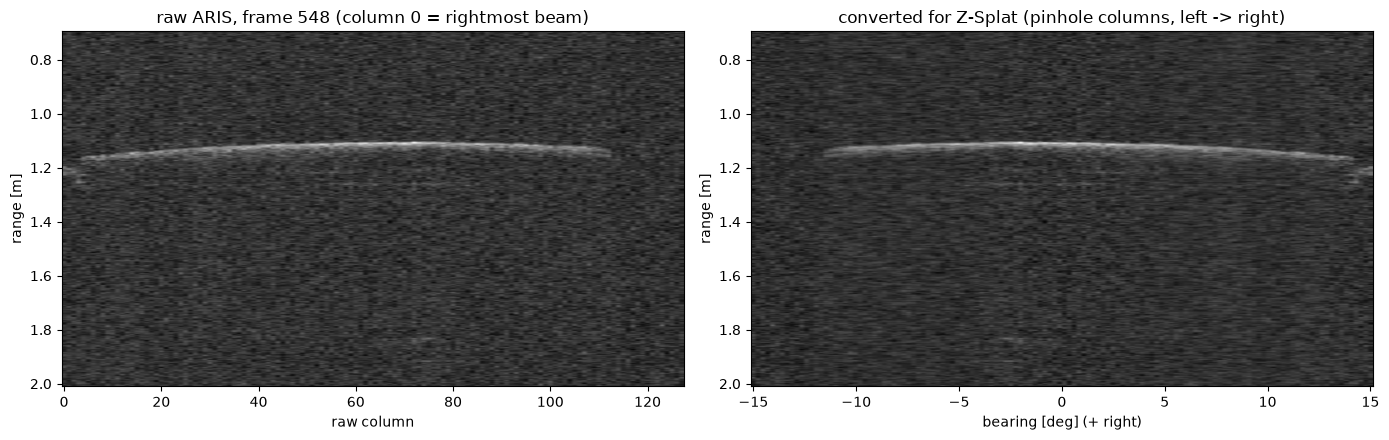

In [22]:
SONAR_W = 128                                                       # one pinhole column per beam
SONAR_HFOV = np.radians(2 * max(abs(e) for e in BEAM_EDGES_DEG))    # pinhole spans the outer beam edges
SONAR_VFOV = np.radians(15.0)                                       # elevation aperture, ARIS Explorer 3000 spec sheet
fx_sonar = SONAR_W / 2 / np.tan(SONAR_HFOV / 2)
col_bearing = np.arctan((np.arange(SONAR_W) + 0.5 - SONAR_W / 2) / fx_sonar)   # pinhole column j, left -> right

# Raw columns reversed = beams sorted left -> right. For each pinhole column: fractional index into that order.
src = np.interp(col_bearing, BEAM_BEARING[::-1], np.arange(128))
k0 = np.minimum(np.floor(src).astype(int), 126)
wk = (src - k0).astype(np.float32)


def sonar_to_zsplat(raw: np.ndarray) -> np.ndarray:
    # (441, 128) uint8 raw ARIS frame -> (441, SONAR_W) float32 in [0, 1]: rows = range bins (near first),
    # columns = pinhole columns left -> right, linearly interpolated between the two nearest beams
    r = raw[:, ::-1].astype(np.float32) / 255
    return (1 - wk) * r[:, k0] + wk * r[:, k0 + 1]


print(f"SONAR_HFOV {np.degrees(SONAR_HFOV):.2f} deg, SONAR_VFOV {np.degrees(SONAR_VFOV):.1f} deg, {SONAR_W} columns")
print(f"pinhole column vs. beam with the same index: up to "
      f"{np.degrees(np.abs(col_bearing - BEAM_BEARING[::-1])).max():.3f} deg apart (beam spacing ≈ {np.median(spacing):.3f} deg)")

j = list(frames.index).index(FRAME)
zs = sonar_to_zsplat(sonar_raw[j])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].imshow(sonar_raw[j], cmap="gray", aspect="auto", extent=[-0.5, 127.5, R_MAX, R_MIN])
ax[0].set(title=f"raw ARIS, frame {FRAME} (column 0 = rightmost beam)", xlabel="raw column", ylabel="range [m]")
b0 = np.degrees(SONAR_HFOV) / 2
ax[1].imshow(zs, cmap="gray", aspect="auto", extent=[-b0, b0, R_MAX, R_MIN])
ax[1].set(title="converted for Z-Splat (pinhole columns, left -> right)", xlabel="bearing [deg] (+ right)",
          ylabel="range [m]")
plt.tight_layout()

**How to read this.** The converted image is the raw image **mirrored** (raw column 0 was the rightmost beam; now
the leftmost column is the leftmost direction) and very slightly stretched sideways (uniform angle → uniform
tan). Left in the converted image is left as seen from the sonar, the same convention as the camera images.

### Step 5 summary

- **Range:** row 0 is the near end (the authors' code, and the pose check: −10 cm residual vs. +39 cm if reversed).
  441 bins of 2.98 mm over `R_MIN`..`R_MAX` ≈ 0.695..2.010 m. Step 6 sets the rasterizer's hard-coded range window
  to exactly this.
- **Bearing:** beam angles from the authors' table (non-uniform, 0.230°–0.239° apart), column 0 = rightmost
  beam (the authors' code, and the arc-tilt check from frame ~300 on).
- **Z-Splat sonar view:** 128 pinhole columns over `SONAR_HFOV` = 30.26° (twice the larger outer beam edge), `SONAR_VFOV` = 15° (spec sheet).
  `sonar_to_zsplat(raw)` turns a raw frame into the `(441 range bins, 128 columns)` image Z-Splat compares against.
- **Not verified here:** the sonar range offset (the target origin is not precise enough; earlier work found
  +1.5…+3 cm using the casing), and the size of the arc tilt (only its sign).
- **Left for step 6:** Z-Splat's own sonar preprocessing in the reader (zeroing near/far rows, an intensity
  threshold, dropping near-empty frames, normalising each column).

## Step 6: write the scene and load it with Z-Splat

Z-Splat's real-sonar path is the `Underwater` reader (`scene/dataset_readers.py`). It is used when the scene folder
contains a file `underwater.keepme.txt`. We write our scene in the same layout the authors used, so their code
reads it, and edit only the parts of their reader that were hard-coded for their own tank:

| File | Content | Read by |
|---|---|---|
| `image/0000.png ...` | undistorted camera images (step 4) | `add_cam` |
| `cameras_sphere.npz` | per image: `world_mat_i = K_new · T_camera_world` (NeuS layout), `scale_mat_i` = identity | `add_cam` |
| `sonar.npz` | cleaned sonar images (range bins x 128 columns), sonar poses, hfov, vfov, view size | `add_sonar` |
| `split.json` | names of the test camera images | `readUnderwaterInfo` |
| `scene.json` | provenance: recording, frames, world shift, all settings below | us |
| `underwater.keepme.txt` | empty marker file that selects the `Underwater` reader | `scene/__init__.py` |

**Decisions for this scene:**

| | choice | why |
|---|---|---|
| frames | every 3rd of the 771 → 257 camera + 257 sonar views | consecutive frames are only 3 mm / 0.18° apart |
| test split | every 8th selected camera image (index % 8 == 4) | all sonar views train; the test images are only for PSNR/SSIM/LPIPS |
| world origin | shifted to the target origin (translation only; still metres, same axes) | the reader seeds its random start points in a ±1.3 m cube around the origin |
| sonar cleaning | per frame: subtract the median background, zero everything below median + 5σ | the authors' threshold (`< 0.01`) would keep 99.998% of our pixels, i.e. pure noise |

**Edits to Z-Splat** (clone `~/Dev/gaussian-splatting-with-depth`, branch `uxo`; every edit is marked `UXO (thesis)`):

- `scene/dataset_readers.py`
  - `readCamerasFromTransformsUnderwater`: read from the scene folder given on the command line (was fixed to
    `./data/underwater`), and use the sonar when `sonar.npz` exists (was switched off).
  - `add_cam`: take the intrinsics from each `world_mat` (was a hard-coded K and image size for the authors' camera);
    remove their fixed 14° `T_adjust` correction.
  - `add_sonar`: read `sonar.npz` (was `real_14deg.mat`). Removed: their quaternion pose chain with a fixed
    translation offset and 90° axis swap (our poses already use the camera axes), the 100-row near/far trimming and
    the `0.01` threshold (cleaning is done here). Kept: dropping frames with fewer than 20 nonzero pixels, and
    scaling each column to max 1.
  - `readUnderwaterInfo`: the `--eval` split reads `split.json`.
- Rasterizer (submodule at the `diff-gs-main-FLS-2` head `c79e907`, branch `uxo`): the range histogram is set to
  our window, 441 bins over `R_MIN`..`R_MAX`, in three places that must agree: `forward.cu`, `backward.cu`
  (`z_index_max`, `z_view_min`, `z_view_max`) and `rasterize_points.cu` (`D`). These are compile-time constants,
  so they are specific to this recording's range window (6d checks them against the notebook).

### 6a. Select frames, shift the world, choose the test images

In [23]:
OUT = Path("prepared/uxo") / f"{TARGET}_{RECORDING}_zsplat"
FRAME_STEP = 3                    # use every 3rd frame
TEST_EVERY = 8                    # every 8th selected camera image is a test image
SONAR_H = 44                      # rows of the pinhole sonar view = elevation samples (the authors' value)
ZSPLAT = Path.home() / "Dev/gaussian-splatting-with-depth"
ZSPLAT_PYTHON = Path.home() / "miniconda3/envs/gaussian_splatting/bin/python"

sel = np.arange(0, N, FRAME_STEP)                        # positions in `frames`
names = [f"{i:04d}" for i in range(len(sel))]            # image/0000.png ... (the reader expects 0, 1, 2, ...)
test_names = [n for i, n in enumerate(names) if i % TEST_EVERY == TEST_EVERY // 2]

WORLD_SHIFT = target.copy()                              # tank coordinates of the new world origin


def shift_world(T: np.ndarray) -> np.ndarray:
    T = T.copy()
    T[:, :3, 3] -= WORLD_SHIFT                           # translation only: metres and axes unchanged
    return T


c2w_cam = shift_world(T_world_camera[sel])               # (n, 4, 4) camera-to-world, x right / y down / z forward
c2w_son = shift_world(T_world_sonar[sel])

print(f"{len(sel)} frames (ARIS {frames.index[sel[0]]}..{frames.index[sel[-1]]}, every {FRAME_STEP}rd), "
      f"{len(test_names)} test images, {len(sel) - len(test_names)} training images")
print(f"world shift (tank coordinates of the new origin) [m]: {WORLD_SHIFT}")
r_cam, r_son = np.linalg.norm(c2w_cam[:, :3, 3], axis=1), np.linalg.norm(c2w_son[:, :3, 3], axis=1)
print(f"distance from the new origin [m]: cameras {r_cam.min():.2f}..{r_cam.max():.2f}, sonar {r_son.min():.2f}..{r_son.max():.2f}"
      f"  (reader's random start points: cube of ±1.3 m)")

257 frames (ARIS 163..931, every 3rd), 32 test images, 225 training images
world shift (tank coordinates of the new origin) [m]: [ 1.2351    1.409233 -1.530784]
distance from the new origin [m]: cameras 0.89..1.04, sonar 1.14..1.31  (reader's random start points: cube of ±1.3 m)


### 6b. Cleaning the sonar images

Z-Splat compares each column of the sonar image with its rendered range histogram, **after scaling both to max 1**
(reader `add_sonar` and `train.py`). That scaling makes noise dangerous: in a column with no echo, the noise maximum
becomes 1 and the whole column looks like "something at every range". The model would then try to put Gaussians
there.

So each frame is cleaned first:

```
background = median of the frame              (the noise floor; ~28 of 255 here)
sigma      = 1.4826 · median |pixel − background|   (robust noise level; ~7.4 here)
cleaned    = pixel − background   where pixel > background + 5·sigma,   else 0
```

5σ is a deliberate, conservative choice: it keeps the target's arc and drops almost all noise. A column with nothing
above the threshold stays all-zero, which tells Z-Splat "no echo here" (the reader leaves all-zero columns at zero).
Weak but real echoes below the threshold are lost.

background 28.0, sigma 7.41  ->  threshold 65 of 255
pixels kept: median 0.46% per frame; columns with an echo: median 52%
frames the reader will drop (< 20 nonzero pixels): 0 of 257


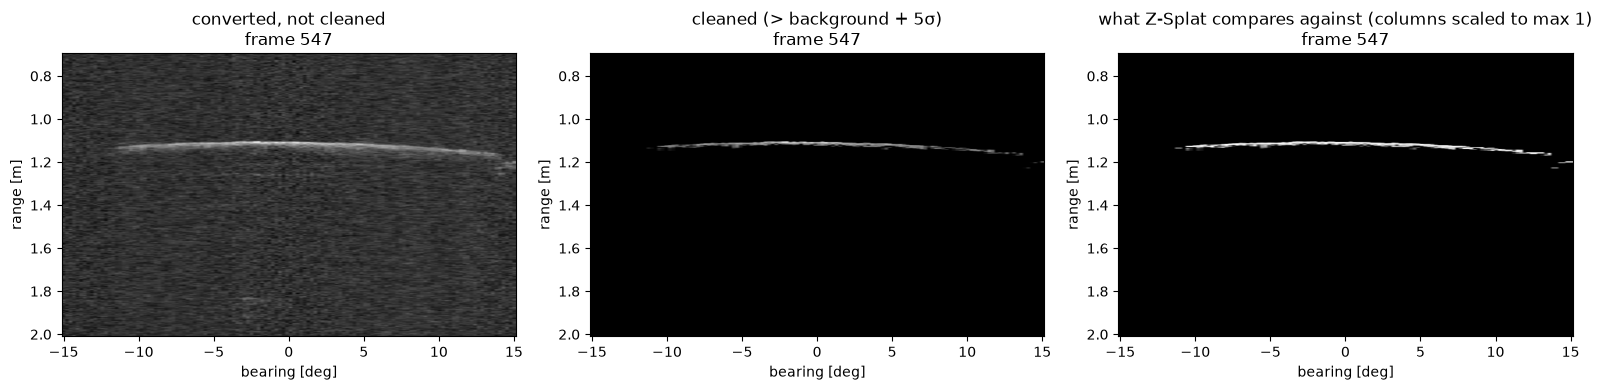

In [24]:
NOISE_K = 5.0


def clean_sonar(raw: np.ndarray) -> tuple[np.ndarray, float, float]:
    raw = raw.astype(np.float32)
    background = np.median(raw)
    sigma = 1.4826 * np.median(np.abs(raw - background))
    return np.where(raw > background + NOISE_K * sigma, raw - background, 0), background, sigma


def column_max_one(im: np.ndarray) -> np.ndarray:
    # what the reader does: scale every nonzero column to max 1
    out, m = im.copy(), im.max(0)
    out[:, m > 0] /= m[m > 0]
    return out


cleaned = [clean_sonar(r) for r in sonar_raw[sel]]
son_imgs = np.stack([sonar_to_zsplat(c) for c, _, _ in cleaned]).astype(np.float32)   # (n, 441, 128)
bgs, sigmas = np.array([b for _, b, _ in cleaned]), np.array([s for _, _, s in cleaned])
nonzero = (son_imgs > 0).sum((1, 2))
print(f"background {np.median(bgs):.1f}, sigma {np.median(sigmas):.2f}  ->  threshold {np.median(bgs + NOISE_K * sigmas):.0f} of 255")
print(f"pixels kept: median {np.median(nonzero / son_imgs[0].size):.2%} per frame; "
      f"columns with an echo: median {np.median((son_imgs > 0).any(1).mean(1)):.0%}")
print(f"frames the reader will drop (< 20 nonzero pixels): {(nonzero < 20).sum()} of {len(sel)}")

j = int(np.argmin(np.abs(frames.index[sel] - FRAME)))
b0 = np.degrees(SONAR_HFOV) / 2
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, im, title in ((ax[0], sonar_to_zsplat(sonar_raw[sel[j]]), "converted, not cleaned"),
                     (ax[1], son_imgs[j], f"cleaned (> background + {NOISE_K:g}σ)"),
                     (ax[2], column_max_one(son_imgs[j]), "what Z-Splat compares against (columns scaled to max 1)")):
    a.imshow(im, cmap="gray", aspect="auto", extent=[-b0, b0, R_MAX, R_MIN])
    a.set(title=f"{title}\nframe {frames.index[sel[j]]}", xlabel="bearing [deg]", ylabel="range [m]")
plt.tight_layout()

**How to read this.** Left: the converted sonar image with its noise floor. Middle: after cleaning, only the arc
(and a few isolated pixels) is left. Right: what the reader hands to the loss: every column with an echo is scaled
to max 1, so the arc becomes a bright line at the same strength in every column, and columns without an echo are
black. Z-Splat learns *where in range* each column has its echo, not how strong it is.

### 6c. Write the scene

Per camera image, `cameras_sphere.npz` stores `world_mat_i = K_new · T_camera_world` (4x4), i.e. the projection from
world points to pixels, the layout from NeuS that the authors' reader expects. The reader splits it back into `K_new`
and the pose with `cv2.decomposeProjectionMatrix`. 6e checks that this round trip gives back our poses.

In [25]:
import shutil

OUT.mkdir(parents=True, exist_ok=True)
if (OUT / "image").exists():
    shutil.rmtree(OUT / "image")                         # only this notebook writes here; start from a clean folder
(OUT / "image").mkdir()
# points3d.ply (the reader's random start points) is kept if it exists, so every run on this scene starts from
# the same points; delete it by hand to draw new ones

K4 = np.eye(4)
K4[:3, :3] = K_new
cams = {}
for i, (k, c2w) in enumerate(zip(sel, c2w_cam)):
    img = cv2.imread(str(REC / frames.gopro_file.iloc[k]))
    cv2.imwrite(str(OUT / "image" / f"{names[i]}.png"), undistort(img))
    cams[f"world_mat_{i}"] = K4 @ np.linalg.inv(c2w)
    cams[f"scale_mat_{i}"] = np.eye(4)
np.savez(OUT / "cameras_sphere.npz", **cams)

np.savez(OUT / "sonar.npz", images=son_imgs, c2w=c2w_son, hfov=SONAR_HFOV, vfov=SONAR_VFOV,
         width=SONAR_W, height=SONAR_H, r_min=R_MIN, r_max=R_MAX)
(OUT / "split.json").write_text(json.dumps({"test": test_names}, indent=1))
(OUT / "underwater.keepme.txt").write_text("")

scene = {
    "dataset": "UXO (dfki-ric/uxo-dataset2024)", "target": TARGET, "recording": RECORDING,
    "aris_frames": [int(i) for i in frames.index[sel]], "frame_step": FRAME_STEP,
    "world": "tank frame shifted by world_shift (metres, z up); sensor axes x right, y down, z forward",
    "world_shift": WORLD_SHIFT.tolist(),
    "camera": {"calibration": GOPRO_MODE, "K": K_new.tolist(), "width": W_new, "height": H_new,
               "fov_x": float(FovX), "fov_y": float(FovY)},
    "sonar": {"width": SONAR_W, "height": SONAR_H, "hfov": float(SONAR_HFOV), "vfov": float(SONAR_VFOV),
              "range_bins": N_BINS, "r_min": float(R_MIN), "r_max": float(R_MAX), "noise_k": NOISE_K},
    "rasterizer_constants": {"z_index_max": N_BINS, "z_view_min": float(R_MIN), "z_view_max": float(R_MAX)},
    "test_every": TEST_EVERY,
}
(OUT / "scene.json").write_text(json.dumps(scene, indent=1))

size = sum(f.stat().st_size for f in OUT.rglob("*") if f.is_file()) / 1e6
print(f"wrote {OUT}: {len(sel)} images ({W_new} x {H_new}), {len(son_imgs)} sonar frames, {size:.0f} MB")

wrote prepared/uxo/20lbs_incendiary_2023-09-21_120653_zsplat: 257 images (1854 x 1042), 257 sonar frames, 382 MB


### 6d. Do the rasterizer constants match this recording?

The range histogram's bins are compile-time constants in the CUDA code. If they don't match the sonar images
(`N_BINS` rows over `R_MIN`..`R_MAX`), Z-Splat would compare range bins that don't line up, or crash on a shape
mismatch. This cell reads the constants from the source files and compares them with the notebook's values.

In [26]:
import re
import subprocess

RAST = ZSPLAT / "submodules" / "diff-gaussian-rasterization"


def constants(path: Path) -> dict:
    text = path.read_text()
    get = lambda name: float(re.search(rf"^\s*(?:const )?(?:int|float) {name} = ([\d.]+);", text, re.M).group(1))
    return {"z_index_max": get("z_index_max"), "z_view_min": get("z_view_min"), "z_view_max": get("z_view_max")}


want = {"z_index_max": N_BINS, "z_view_min": R_MIN, "z_view_max": R_MAX}
for f in ("cuda_rasterizer/forward.cu", "cuda_rasterizer/backward.cu"):
    got = constants(RAST / f)
    ok = all(abs(got[k] - want[k]) < 1e-6 for k in want)
    print(f"{f:28s} {got}  {'OK' if ok else 'MISMATCH, expected ' + str(want)}")
D = int(re.search(r"const int D = (\d+);", (RAST / "rasterize_points.cu").read_text()).group(1))
print(f"{'rasterize_points.cu':28s} D = {D}  {'OK' if D == N_BINS else 'MISMATCH, expected ' + str(N_BINS)}")

git = lambda repo, *a: subprocess.run(["git", "-C", str(repo), *a], capture_output=True, text=True).stdout.strip()
for repo in (ZSPLAT, RAST):
    print(f"\n{repo.name}: branch {git(repo, 'branch', '--show-current')}, based on {git(repo, 'rev-parse', '--short', 'HEAD')}")
    print(git(repo, "diff", "--stat"))

cuda_rasterizer/forward.cu   {'z_index_max': 441.0, 'z_view_min': 0.6949353, 'z_view_max': 2.0102421}  OK
cuda_rasterizer/backward.cu  {'z_index_max': 441.0, 'z_view_min': 0.6949353, 'z_view_max': 2.0102421}  OK
rasterize_points.cu          D = 441  OK

gaussian-splatting-with-depth: branch uxo, based on d9dac70
scene/dataset_readers.py               | 100 +++++++++++++--------------------
 submodules/diff-gaussian-rasterization |   2 +-
 2 files changed, 39 insertions(+), 63 deletions(-)

diff-gaussian-rasterization: branch uxo, based on c79e907
cuda_rasterizer/backward.cu | 7 ++++---
 cuda_rasterizer/forward.cu  | 8 +++++---
 rasterize_points.cu         | 2 +-
 3 files changed, 10 insertions(+), 7 deletions(-)


### 6e. Final check: load the scene with Z-Splat's own reader

Z-Splat runs in its own Python environment (`gaussian_splatting`), so the cell below runs the **unmodified call path**
`readUnderwaterInfo(scene, white_background=False, eval=True)` in that environment and saves what the reader
produced. Then we compare it with what this notebook intended:

- **counts**: training / test camera images, sonar views (minus frames dropped by the reader);
- **camera poses and fields of view**: the reader's `R`, `T` (world-to-camera, `R` stored transposed) and
  `FovX`, `FovY` against ours, after the round trip through `world_mat` and `decomposeProjectionMatrix`;
- **projection**: where the reader's camera model puts the target (now the world origin), in pixels, against
  `K_new` and our pose;
- **sonar**: the reader's sonar poses, and the per-column-scaled images, against ours; their shape must equal the
  rasterizer's `(z_index_max, width)`.

The reader also writes its random start points (`points3d.ply`, 100k points in ±1.3 m) into the scene on first load.
It does not set a random seed, so they differ each time the file is regenerated.

In [27]:
import tempfile

check = tempfile.NamedTemporaryFile(suffix=".npz", delete=False).name
reader_code = f"""
import sys, numpy as np
sys.path.insert(0, {str(ZSPLAT)!r})
from scene.dataset_readers import readUnderwaterInfo
info = readUnderwaterInfo({str(OUT.resolve())!r}, False, True)
out = {{}}
for split, cams in (("train", info.train_cameras), ("test", info.test_cameras)):
    out[split + "_R"] = np.stack([c.R for c in cams]); out[split + "_T"] = np.stack([c.T for c in cams])
    out[split + "_fov"] = np.array([[c.FovX, c.FovY] for c in cams], float)
    out[split + "_size"] = np.array([[c.width, c.height] for c in cams])
    out[split + "_sonar"] = np.array([c.is_sonar for c in cams])
    out[split + "_uid"] = np.array([c.uid for c in cams])
    out[split + "_name"] = np.array([str(c.image_name) for c in cams])
son = [c for c in info.train_cameras if c.is_sonar]
out["sonar_depth"] = np.stack([c.depth[1] for c in son])
out["n_points"] = len(info.point_cloud.points)
out["points_min"], out["points_max"] = info.point_cloud.points.min(0), info.point_cloud.points.max(0)
out["radius"] = info.nerf_normalization["radius"]
np.savez({check!r}, **out)
"""
run = subprocess.run([str(ZSPLAT_PYTHON), "-c", reader_code], capture_output=True, text=True)
print(run.stdout.strip()[-500:], run.stderr.strip()[-2000:], sep="\n")
r = np.load(check)

# counts
n_cam_train, n_son = (~r["train_sonar"]).sum(), r["train_sonar"].sum()
print(f"reader: {n_cam_train} training images, {len(r['test_sonar'])} test images (all camera: {not r['test_sonar'].any()}), "
      f"{n_son} sonar views; expected {len(sel) - len(test_names)}, {len(test_names)}, {(nonzero >= 20).sum()}")
assert set(r["test_name"]) == set(test_names)

# camera poses, fields of view, projection of the target (world origin)
errs = {"R": 0.0, "T [m]": 0.0, "FovX/FovY [deg]": 0.0, "target pixel [px]": 0.0}
for split in ("train", "test"):
    for R, T, fov, size, s, name in zip(r[split + "_R"], r[split + "_T"], r[split + "_fov"], r[split + "_size"],
                                        r[split + "_sonar"], r[split + "_name"]):
        if s:
            continue
        w2c = np.linalg.inv(c2w_cam[names.index(name)])
        errs["R"] = max(errs["R"], np.abs(R.T - w2c[:3, :3]).max())
        errs["T [m]"] = max(errs["T [m]"], np.abs(T - w2c[:3, 3]).max())
        errs["FovX/FovY [deg]"] = max(errs["FovX/FovY [deg]"], np.degrees(np.abs(fov - [FovX, FovY])).max())
        f = size / 2 / np.tan(fov / 2)                       # the reader's pinhole: focal from FoV, centre = size / 2
        uv_reader = f * T[:2] / T[2] + size / 2               # target = world origin -> camera coordinates = T
        uv_ours = (K_new @ w2c[:3, 3])[:2] / w2c[2, 3]
        errs["target pixel [px]"] = max(errs["target pixel [px]"], np.abs(uv_reader - uv_ours).max())
print("camera, largest difference reader vs. notebook:", {k: f"{v:.2e}" for k, v in errs.items()})

# sonar poses and images
son = r["train_sonar"]
R_s, T_s, uid_s = r["train_R"][son], r["train_T"][son], r["train_uid"][son]
w2c_s = np.linalg.inv(c2w_son[uid_s])
print(f"sonar, largest difference reader vs. notebook: R {np.abs(np.transpose(R_s, (0, 2, 1)) - w2c_s[:, :3, :3]).max():.2e}, "
      f"T {np.abs(T_s - w2c_s[:, :3, 3]).max():.2e} m, "
      f"images {np.abs(r['sonar_depth'] - np.stack([column_max_one(son_imgs[u]) for u in uid_s])).max():.2e}")
print(f"sonar image shape {r['sonar_depth'].shape[1:]} = (z_index_max, width) {(N_BINS, SONAR_W)}: "
      f"{r['sonar_depth'].shape[1:] == (N_BINS, SONAR_W)}; view {r['train_size'][son][0]}, "
      f"FovX/FovY {np.degrees(r['train_fov'][son][0]).round(2)} deg")
print(f"sonar → target distance from the reader's poses: {np.linalg.norm(T_s, axis=1).min():.3f}..{np.linalg.norm(T_s, axis=1).max():.3f} m "
      f"(step 5a: {pred_range[sel].min():.3f}..{pred_range[sel].max():.3f} m)")
print(f"start points: {int(r['n_points'])} in {r['points_min'].round(2)}..{r['points_max'].round(2)}; "
      f"scene radius used for densification: {float(r['radius']):.2f} m")

Reading Transforms
SONAR+CAMERA
Generating random point cloud (100000)...

reader: 225 training images, 32 test images (all camera: True), 257 sonar views; expected 225, 32, 257
camera, largest difference reader vs. notebook: {'R': '5.69e-08', 'T [m]': '9.19e-08', 'FovX/FovY [deg]': '3.82e-14', 'target pixel [px]': '9.54e-05'}
sonar, largest difference reader vs. notebook: R 3.33e-16, T 4.44e-16 m, images 0.00e+00
sonar image shape (441, 128) = (z_index_max, width) (441, 128): True; view [128  44], FovX/FovY [30.26 15.  ] deg
sonar → target distance from the reader's poses: 1.143..1.307 m (step 5a: 1.143..1.307 m)
start points: 100000 in [-1.3 -1.3 -1.3]..[1.3 1.3 1.3]; scene radius used for densification: 1.31 m


### Step 6 summary

The scene loads with Z-Splat's own reader, and what comes out matches what this notebook computed: the camera and
sonar poses survive the round trip, the fields of view are ours, the target projects to the same pixel, and the
sonar images have exactly the shape of the rasterizer's range histogram.

**Before training** (not done in this notebook):

- **Rebuild the rasterizer** in the `gaussian_splatting` environment. The installed version is still the old
  patched build, so it does not have the new range constants. The build needs CUDA 11.8 and gcc 11.
- **Training resolution.** Camera views wider than 512 px also compute the 441-bin histogram per pixel, which made
  full-resolution training ~16x slower before. Options: train at reduced resolution (`-r`), or re-apply the earlier
  patch that skips the histogram for camera views.
- The rasterizer's range constants are specific to this recording's window (0.695–2.010 m). Another recording may
  need other values; 6d shows a mismatch.

## Step 7: camera poses from COLMAP, sonar poses from those

**Why.** Training camera-only with the gantry poses (step 3) gave blurry, ghosted images, **also on the training
views**. That means the model could not fit even the images it trained on: the poses don't agree with each other
about where things are. Step 3d could not catch this, because its check only rules out errors above ~10° / 6°.

**The plan.**

```
COLMAP (images only)   →  camera poses that agree with each other, in an arbitrary frame and scale
align to the gantry    →  the same poses, in metres, in our world frame (positions only)
camera pose · T_camera_sonar (calibration)  →  sonar poses
```

COLMAP is a structure-from-motion program. It finds the same image features in many images and solves for the camera
poses (and sparse 3D points) that make all those observations agree. We give it our pinhole camera `K_new` from step 4
and keep it **fixed**, so it solves only for poses and points, and the camera model stays the one Z-Splat gets.

### 7a. Run COLMAP on the 257 undistorted images

Settings: one shared PINHOLE camera with `K_new`, GPU SIFT features, exhaustive matching (every image against every
other), and the mapper with focal length, principal point and extra parameters not refined. The run takes ~20 min,
so the cell skips it if the reconstruction already exists.

In [ ]:
import shutil
import subprocess
import time

COLMAP = Path.home() / "miniconda3/envs/nerfstudio/bin/colmap"     # COLMAP build with CUDA (nerfstudio environment)
SFM = Path("prepared/uxo") / f"{TARGET}_{RECORDING}_colmap_sfm"


def colmap(*args) -> subprocess.CompletedProcess:
    t0 = time.time()
    r = subprocess.run([str(COLMAP), *args], capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-2000:], r.stderr[-2000:])
        raise RuntimeError(f"colmap {args[0]} failed")
    print(f"colmap {args[0]:20s} {time.time() - t0:6.0f} s")
    return r


if not (SFM / "sparse" / "0" / "images.txt").exists():
    if SFM.exists():
        shutil.rmtree(SFM)
    (SFM / "images").mkdir(parents=True)
    for n in names:                                                  # the scene's undistorted images, as links
        (SFM / "images" / f"{n}.png").symlink_to((OUT / "image" / f"{n}.png").resolve())
    (SFM / "sparse").mkdir()
    db = str(SFM / "database.db")
    colmap("feature_extractor", "--database_path", db, "--image_path", str(SFM / "images"),
           "--ImageReader.camera_model", "PINHOLE", "--ImageReader.single_camera", "1",
           "--ImageReader.camera_params", ",".join(f"{v:.6f}" for v in (K_new[0, 0], K_new[1, 1], K_new[0, 2], K_new[1, 2])),
           "--SiftExtraction.use_gpu", "1")
    colmap("exhaustive_matcher", "--database_path", db, "--SiftMatching.use_gpu", "1")
    colmap("mapper", "--database_path", db, "--image_path", str(SFM / "images"), "--output_path", str(SFM / "sparse"),
           "--Mapper.ba_refine_focal_length", "0", "--Mapper.ba_refine_principal_point", "0",
           "--Mapper.ba_refine_extra_params", "0")
    for m in sorted((SFM / "sparse").iterdir()):
        colmap("model_converter", "--input_path", str(m), "--output_path", str(m), "--output_type", "TXT")

for m in sorted((SFM / "sparse").iterdir()):
    stats = colmap("model_analyzer", "--path", str(m)).stderr.strip().splitlines()
    print(f"model {m.name}:", "; ".join(l.split("] ")[-1] for l in stats if "] " in l)[:400])

**How to read this.** One model with all 257 images registered means COLMAP found one consistent solution for the
whole pass. The mean reprojection error (~1 px) is how far, on average, the 3D points land from the features they
were triangulated from: with a fixed camera model, ~1 px means the poses explain the images well.

### 7b. Put COLMAP into metres, and measure how the gantry orientation is off

COLMAP's frame and scale are arbitrary. We fit **one** similarity transform (scale, rotation, translation) that maps
the COLMAP camera *positions* onto the gantry camera *positions* (Umeyama's method, least squares). Only positions
are used: they are what we trust from the gantry (earlier work found ~2 cm agreement). Orientations are the suspect.

Then, frame by frame, we compare the orientations. The rotation that turns the gantry camera into the COLMAP camera
can be written in two ways:

- in **camera axes**, `R_gantryᵀ · R_colmap`: constant if the camera sits on the rig at a fixed, wrong angle (a
  mount error);
- in **world axes**, `R_colmap · R_gantryᵀ`: constant if the whole scene is just turned, which the alignment would
  already have absorbed.

If neither is constant, the error changes with the rig's motion (e.g. with the pan angle).

In [ ]:
def read_colmap_images(model_dir: Path) -> dict[str, np.ndarray]:
    # images.txt: two lines per image; the first is IMAGE_ID QW QX QY QZ TX TY TZ CAMERA_ID NAME, the world-to-camera
    # rotation (quaternion, w first) and translation in COLMAP's frame. Returns image name (stem) -> camera-to-world 4x4.
    lines = [l for l in (model_dir / "images.txt").read_text().splitlines() if not l.startswith("#")]
    poses = {}
    for l in lines[::2]:
        v = l.split()
        w2c = np.eye(4)
        w2c[:3, :3] = Rotation.from_quat([float(v[2]), float(v[3]), float(v[4]), float(v[1])]).as_matrix()
        w2c[:3, 3] = [float(x) for x in v[5:8]]
        poses[Path(v[9]).stem] = np.linalg.inv(w2c)
    return poses


def umeyama(src: np.ndarray, dst: np.ndarray) -> tuple[float, np.ndarray, np.ndarray]:
    # similarity (scale s, rotation R, translation t) minimising sum |s R src + t - dst|^2 (Umeyama 1991)
    mu_s, mu_d = src.mean(0), dst.mean(0)
    a, b = src - mu_s, dst - mu_d
    U, S_, Vt = np.linalg.svd(b.T @ a / len(src))
    Dg = np.diag([1, 1, np.sign(np.linalg.det(U @ Vt))])                 # no reflections
    R = U @ Dg @ Vt
    s = np.trace(np.diag(S_) @ Dg) / (a ** 2).sum(1).mean()
    return s, R, mu_d - s * R @ mu_s


model = max((SFM / "sparse").iterdir(), key=lambda m: len(read_colmap_images(m)))   # the largest model
c2w_colmap_raw = read_colmap_images(model)
registered = [i for i, n in enumerate(names) if n in c2w_colmap_raw]
print(f"COLMAP model {model.name}: {len(registered)} of {len(names)} images registered")

pos_colmap = np.stack([c2w_colmap_raw[names[i]][:3, 3] for i in registered])
pos_gantry = c2w_cam[registered, :3, 3]                                  # gantry camera positions (shifted world, m)
s_al, R_al, t_al = umeyama(pos_colmap, pos_gantry)

c2w_colmap = np.tile(np.eye(4), (len(registered), 1, 1))                 # COLMAP camera poses in our world, metres
for k, i in enumerate(registered):
    raw = c2w_colmap_raw[names[i]]
    c2w_colmap[k, :3, :3] = R_al @ raw[:3, :3]                           # turn the axes (no scaling of a rotation)
    c2w_colmap[k, :3, 3] = s_al * R_al @ raw[:3, 3] + t_al               # move and scale the position into metres

pos_res = np.linalg.norm(c2w_colmap[:, :3, 3] - pos_gantry, axis=1) * 100
print(f"alignment: scale {s_al:.4f} m per COLMAP unit; position difference to the gantry: median {np.median(pos_res):.1f} cm, "
      f"95% {np.percentile(pos_res, 95):.1f} cm, max {pos_res.max():.1f} cm")

R_g, R_c = c2w_cam[registered, :3, :3], c2w_colmap[:, :3, :3]
D_cam = Rotation.from_matrix(np.einsum("nji,njk->nik", R_g, R_c))       # R_gantry^T R_colmap  (camera axes)
E_world = Rotation.from_matrix(np.einsum("nij,nkj->nik", R_c, R_g))     # R_colmap R_gantry^T  (world axes)
for name, Q in (("camera axes", D_cam), ("world axes", E_world)):
    mean = Q.mean()
    spread = np.degrees((mean.inv() * Q).magnitude())
    print(f"gantry -> COLMAP rotation in {name}: mean {np.degrees(mean.magnitude()):.2f} deg, rotation vector "
          f"{np.degrees(mean.as_rotvec()).round(2)} deg; spread around the mean: median {np.median(spread):.2f}, "
          f"95% {np.percentile(spread, 95):.2f} deg")

looks_down = lambda R: np.degrees(np.arcsin(-R[:, 2, 2]))                # angle of the viewing direction below horizontal
print(f"camera looks down: gantry {np.median(looks_down(R_g)):.2f} deg, COLMAP {np.median(looks_down(R_c)):.2f} deg "
      f"({looks_down(R_c).min():.2f}..{looks_down(R_c).max():.2f})")

fi = frames.index[sel][registered]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
for a, Q, title in ((ax[0], D_cam, "camera axes: x right, y down, z forward"), (ax[1], E_world, "world axes: x, y, z up")):
    rv = np.degrees(Q.as_rotvec())
    for k, axis in enumerate("xyz"):
        a.plot(fi, rv[:, k], label=f"about {axis}")
    a.axhline(0, color="k", lw=0.5)
    a.set(title=f"gantry → COLMAP rotation, {title}", xlabel="frame index", ylabel="rotation vector [deg]")
    a.legend(fontsize=8)
ax[2].plot(fi, pos_res)
ax[2].set(title="position difference after alignment", xlabel="frame index", ylabel="cm")
plt.tight_layout()

**How to read this**

- **Positions agree to ~2 cm** (median; up to 6 cm). The gantry path and the COLMAP path have the same shape, so
  the scale (and with it, metres for the sonar) is well determined. The residual is not random noise: it drifts
  smoothly along the pass, so one of the two paths is slightly bent relative to the other. That's at the level of a
  few cm and is not settled here.
- **Orientations differ by ~4.5° on average, and not by a constant.** Neither form of the difference stays fixed:
  - **About the camera's x axis (pitch): steady at +2…+4°.** In COLMAP the camera looks down **~18.5°**, the gantry
    chain says **22.0°**. This part behaves like a fixed mount error: the camera points ~3.5° higher than the
    calibration file assumes. (`transforms.yaml` has a commented-out ~4° rotation of the GoPro mount about the same
    axis: the authors suspected something like this. Its sign would tilt the camera *down*, so it does not simply
    match; confirm before citing.)
  - **About the camera's y (yaw) and z (roll) axes: varying by several degrees along the pass**, in steps and wiggles
    that follow the rotator's motion (the roll part correlates strongly with the pan angle). This part is not a fixed
    mount angle; it comes from the rig's moving parts (e.g. a pan axis that is not exactly vertical, or errors in
    the logged pan).
- **Why this blurs the reconstruction.** A pose error that is different in every frame means the rays of different
  images no longer meet at the same points. 3DGS can't fit all images at once and averages, which gives the blur and
  ghosting we saw.

**What it means for the sonar poses.** The errors that move with the rig (yaw, roll) are shared by camera and sonar,
since both sit on the same rotator. Taking the sonar pose from the COLMAP camera pose corrects them for the sonar
too. The steady ~3.5° pitch is the open question: if it is the GoPro mount alone, the calibration's camera→sonar
transform is wrong by that much and the sonar would inherit it; if it is the rig (e.g. a tilt offset), the sonar
shares it and COLMAP fixes it. 7c tests this against the sonar images.

### 7c. Sonar poses from the COLMAP camera poses, and two checks

The sonar pose is the COLMAP camera pose followed by the fixed camera → sonar transform from the calibration
(step 3a: the sonar sits 28 cm behind and 15 cm below the camera, with the same orientation):

```
T_world_sonar = T_world_camera(COLMAP, in metres) · T_camera_sonar,    T_camera_sonar = T_ar3_camera⁻¹ · T_ar3_sonar
```

**Assumption:** the calibration's camera → sonar transform is right. If the steady ~3.5° pitch difference from 7b
is the GoPro mount alone, it isn't, and the sonar poses inherit that error.

Two checks use COLMAP's own 3D points, moved into metres with the same alignment:

1. **Floor.** The tank floor shows up as a large flat patch of points. In the real tank it should be parallel to the
   camera path (the gantry moves at constant height, and the floor is assumed level).
2. **Casing range and bearing.** The orange points around the origin are the casing. For every sonar frame we
   predict, per beam, the range of the nearest casing point inside the sonar's fan, and compare with the measured
   arc, for **both** pose sources (gantry vs. COLMAP + calibration).

In [ ]:
rows = [l.split() for l in (model / "points3D.txt").read_text().splitlines() if not l.startswith("#")]
pts = np.array([[float(v) for v in r[1:7]] for r in rows])                # X Y Z R G B in COLMAP's frame
xyz = (s_al * (R_al @ pts[:, :3].T)).T + t_al                             # into our world, metres
rgb = pts[:, 3:6]
print(f"{len(xyz)} COLMAP points")

# casing: orange points within 0.4 m of the target origin (= the world origin)
casing = (np.linalg.norm(xyz, axis=1) < 0.4) & (rgb[:, 0] > 90) & (rgb[:, 0] > 1.25 * rgb[:, 2]) & (rgb[:, 0] >= rgb[:, 1])
print(f"casing points: {casing.sum()}, extent {xyz[casing].min(0).round(2)} .. {xyz[casing].max(0).round(2)} m")

# floor: the plane with the most points within 1 cm (RANSAC), among points below the casing, refined with SVD
rng = np.random.default_rng(0)
cand = np.where((xyz[:, 2] < -0.15) & (np.hypot(xyz[:, 0], xyz[:, 1]) < 1.2))[0]
best = (0, None, None)
for _ in range(2000):
    a, b, c = xyz[rng.choice(cand, 3, replace=False)]
    nrm = np.cross(b - a, c - a)
    if np.linalg.norm(nrm) < 1e-9:
        continue
    nrm /= np.linalg.norm(nrm)
    k = (np.abs((xyz[cand] - a) @ nrm) < 0.01).sum()
    if k > best[0]:
        best = (k, nrm, a)
inl = cand[np.abs((xyz[cand] - best[2]) @ best[1]) < 0.01]
floor_c = xyz[inl].mean(0)
floor_n = np.linalg.svd(xyz[inl] - floor_c)[2][2]
floor_n *= np.sign(floor_n[2])
flat = np.abs((xyz - floor_c) @ floor_n) < 0.05
print(f"floor: {len(inl)} points within 1 cm of the plane; rms of all points within 5 cm: "
      f"{1e3 * ((xyz[flat] - floor_c) @ floor_n).std():.0f} mm; {-(floor_c @ floor_n):.2f} m below the target origin")

path_n = np.linalg.svd(c2w_colmap[:, :3, 3] - c2w_colmap[:, :3, 3].mean(0))[2][2]
print(f"angle between the floor and the camera path: {np.degrees(np.arccos(abs(path_n @ floor_n))):.1f} deg "
      f"(expected ~0 if the floor is level)")
down_floor = np.degrees(np.arcsin(-c2w_colmap[:, :3, 2] @ floor_n))
print(f"COLMAP camera looks down {np.median(looks_down(R_c)):.1f} deg relative to the camera path "
      f"({looks_down(R_c).min():.1f}..{looks_down(R_c).max():.1f}), {np.median(down_floor):.1f} deg relative to the floor "
      f"({down_floor.min():.1f}..{down_floor.max():.1f})")

**How to read this: an unresolved finding.** The floor is flat (~2 cm rms), but in COLMAP it is tilted **~10°**
against the camera path. Relative to the path, the camera's downward angle is steady (~18.5°), as it should be with
a fixed rotator tilt. Relative to the COLMAP floor it swings by ~13° along the pass. So COLMAP's floor and the rig's
"level" disagree. Two explanations:

- the tank floor really slopes relative to the gantry (unlikely at 10°: ~20 cm of height change across the pass);
- COLMAP's geometry is skewed away from the target, e.g. because the camera model (step 4, `wide` calibration, held
  fixed here) is slightly wrong: a wrong focal length stretches depth relative to width and tilts oblique surfaces.

This is **not resolved here**. A test would be to re-run COLMAP with the focal length free and see if the floor
becomes level. What matters for Z-Splat is whether the geometry is right **near the target**, which is what the
sonar can test (next cell).

In [ ]:
T_camera_sonar = np.linalg.inv(T_ar3_camera) @ T_ar3_sonar
c2w_son_colmap = c2w_colmap @ T_camera_sonar                              # (n, 4, 4) sonar poses from COLMAP

C = np.c_[xyz[casing], np.ones(casing.sum())]
raw_sel = sonar_raw[sel][registered].astype(np.int16)
peak_img = np.clip(raw_sel - np.median(raw_sel, axis=(1, 2), keepdims=True), 0, None)
peak, peak_row = peak_img.max(1), peak_img.argmax(1)                      # (n, 128): strongest return per raw column
PEAK_MIN = NOISE_K * np.median(sigmas)                                    # same 5 sigma as the cleaning in 6b


def casing_check(c2ws: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    # per frame: median (measured arc range - nearest casing point range) over beams where both exist [cm],
    # and the overlap (IoU) of the beams where the casing is predicted vs. where an echo is measured
    res, iou = [], []
    for k in range(len(c2ws)):
        p = (np.linalg.inv(c2ws[k]) @ C.T).T[:, :3]
        r, b = np.linalg.norm(p, axis=1), np.arctan2(p[:, 0], p[:, 2])
        e = np.arctan2(-p[:, 1], np.hypot(p[:, 0], p[:, 2]))
        inside = (np.abs(e) < SONAR_VFOV / 2) & (np.abs(b) < SONAR_HFOV / 2)
        beam = np.abs(b[inside, None] - BEAM_BEARING[None]).argmin(1)
        pred = np.full(128, np.inf)
        np.minimum.at(pred, beam, r[inside])
        pred[np.isinf(pred)] = np.nan
        meas = np.where(peak[k] > PEAK_MIN, ranges[peak_row[k]], np.nan)
        both = ~np.isnan(pred) & ~np.isnan(meas)
        res.append(np.median(meas[both] - pred[both]) * 100 if both.sum() > 5 else np.nan)
        iou.append((~np.isnan(pred) & ~np.isnan(meas)).sum() / max(1, (~np.isnan(pred) | ~np.isnan(meas)).sum()))
    return np.array(res), np.array(iou)


checks = {"gantry sonar poses": casing_check(c2w_son[registered]),
          "COLMAP camera + calibration": casing_check(c2w_son_colmap)}
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2))
for name, (res, iou) in checks.items():
    print(f"{name:28s} arc range - casing: median {np.nanmedian(res):+.1f} cm, std {np.nanstd(res):.1f} cm | "
          f"beam overlap (IoU): median {np.median(iou):.2f}")
    ax[0].plot(fi, res, ".-", ms=3, lw=0.7, label=name)
    ax[1].plot(fi, iou, ".-", ms=3, lw=0.7, label=name)
ax[0].set(xlabel="frame index", ylabel="arc range - nearest casing point [cm]")
ax[1].set(xlabel="frame index", ylabel="beam overlap (IoU)")
ax[0].legend(fontsize=8)
plt.tight_layout()

**How to read this**

- **Range:** with both pose sources, the measured arc lies a few cm *behind* the nearest casing point (median
  +4…+5 cm). Neither is flat along the pass: the gantry residual drifts from about −1 to +7 cm; the COLMAP-based one
  stays at +2…+9 cm with less scatter. The steady few-cm offset in both is either a sonar range offset or the
  camera-visible casing points not being exactly the surface the sonar hears; it is not settled here.
- **Bearing:** the COLMAP-based poses put the casing in the right beams slightly more often (overlap 0.64 vs 0.55),
  mainly in the second half of the pass.
- **Conclusion:** the sonar does not contradict "COLMAP camera pose + calibration camera → sonar"; it fits at least
  as well as the gantry poses. It can't settle the pitch question, because range hardly changes with a few degrees
  of pitch.

### 7d. Write the COLMAP scenes

Two scenes, identical to the step 6 scenes except for the poses: the same images, sonar images, split and random
start points (`image/` and `points3d.ply` are links to the step 6 scene). So a comparison with the gantry runs
changes only the poses.

In [ ]:
assert len(registered) == len(names), "some images were not registered by COLMAP; they would need to be dropped"

K4 = np.eye(4)
K4[:3, :3] = K_new
OUT_COL = OUT.with_name(OUT.name + "_colmap")
for out_dir, with_sonar in ((OUT_COL, True), (OUT_COL.with_name(OUT_COL.name + "_camonly"), False)):
    if out_dir.exists():
        shutil.rmtree(out_dir)                                           # only this notebook writes here
    out_dir.mkdir(parents=True)
    for f in ("image", "points3d.ply", "split.json", "underwater.keepme.txt"):
        (out_dir / f).symlink_to(Path("..") / OUT.name / f)              # same images, start points and split
    np.savez(out_dir / "cameras_sphere.npz",
             **{f"world_mat_{i}": K4 @ np.linalg.inv(c2w_colmap[i]) for i in range(len(names))},
             **{f"scale_mat_{i}": np.eye(4) for i in range(len(names))})
    if with_sonar:
        np.savez(out_dir / "sonar.npz", images=son_imgs, c2w=c2w_son_colmap, hfov=SONAR_HFOV, vfov=SONAR_VFOV,
                 width=SONAR_W, height=SONAR_H, r_min=R_MIN, r_max=R_MAX)
    scene_col = json.loads((OUT / "scene.json").read_text())
    scene_col["poses"] = {
        "camera": "COLMAP (fixed K_new), similarity-aligned to the gantry camera positions",
        "sonar": "COLMAP camera pose @ calibration camera->sonar" if with_sonar else "none (camera only)",
        "colmap_model": str(model), "alignment_scale": float(s_al), "alignment_R": R_al.tolist(),
        "alignment_t": t_al.tolist(), "position_residual_cm_median": float(np.median(pos_res)),
    }
    (out_dir / "scene.json").write_text(json.dumps(scene_col, indent=1))
    print(f"wrote {out_dir}")

### 7e. Check: load the COLMAP scene with Z-Splat's reader

The same round-trip check as 6e: the reader's camera and sonar poses must equal ours.

In [ ]:
reader_code_col = reader_code.replace(repr(str(OUT.resolve())), repr(str(OUT_COL.resolve())))
run = subprocess.run([str(ZSPLAT_PYTHON), "-c", reader_code_col], capture_output=True, text=True)
print(run.stdout.strip()[-300:], run.stderr.strip()[-2000:], sep="\n")
r = np.load(check)

cam_err = 0.0
for split in ("train", "test"):
    for R, T, s, name in zip(r[split + "_R"], r[split + "_T"], r[split + "_sonar"], r[split + "_name"]):
        if not s:
            w2c = np.linalg.inv(c2w_colmap[names.index(name)])
            cam_err = max(cam_err, np.abs(R.T - w2c[:3, :3]).max(), np.abs(T - w2c[:3, 3]).max())
son = r["train_sonar"]
w2c_s = np.linalg.inv(c2w_son_colmap[r["train_uid"][son]])
son_err = max(np.abs(np.transpose(r["train_R"][son], (0, 2, 1)) - w2c_s[:, :3, :3]).max(),
              np.abs(r["train_T"][son] - w2c_s[:, :3, 3]).max())
print(f"reader: {(~r['train_sonar']).sum()} training images, {len(r['test_sonar'])} test images, {son.sum()} sonar views")
print(f"largest difference reader vs. notebook: cameras {cam_err:.1e}, sonar {son_err:.1e}; "
      f"sonar image shape {r['sonar_depth'].shape[1:]}")

### Step 7 summary

- **COLMAP poses** (fixed camera model) register all images at ~1 px and are aligned to the gantry positions in
  metres (~2 cm). The gantry orientations differ from them by ~4.5°, partly as a steady pitch (camera ~3.5° higher
  than the calibration says) and partly varying with the rotator's motion, which explains the blurry gantry-pose
  reconstruction.
- **Sonar poses** = COLMAP camera pose · calibration camera → sonar. They fit the sonar's casing echoes at least as
  well as the gantry poses (range within a few cm, slightly better bearing).
- **Open:** COLMAP's floor is tilted ~10° against the camera path (cause unknown: sloped floor, or a slightly wrong
  camera model); whether the steady pitch is the GoPro mount alone; a few-cm range offset of the sonar.
- **Scenes:** `..._zsplat_colmap` (camera + sonar) and `..._zsplat_colmap_camonly`, with the same images, sonar
  images, split and start points as the gantry scenes.